<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-05/lab-016-pca-tsne-clustering.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
**Author:** Marcin Płodzień <br>
**Lab:** 016 &nbsp;·&nbsp; **Lecture:** 5 (*Unsupervised learning*)
<hr/>

# Lab 016 — PCA, t-SNE and clustering

Until now every image came with a label, and a network learned to predict it. Here we keep only the data, $\{\mathbf x_i\}_{i=1}^{n}$, and ask what can be learned without labels: which few variables describe a sample, and whether the samples form groups.

We start from the observation that an image of the MNIST data set (Modified National Institute of Standards and Technology database: 70 000 handwritten digits of $28\times28$ grey pixels) is a point in $\mathbb R^{784}$, while the digits fill only a thin part of that space. The first method that exploits this is principal component analysis (PCA), a linear projection onto the few directions along which the data vary most, which we derive from variance maximisation and compute with `jnp.linalg.eigh` and `jnp.linalg.svd`. A linear projection squeezes curved structure together, so we then turn to t-distributed stochastic neighbour embedding (t-SNE), a non-linear map that keeps neighbours (the name refers to the probabilistic, *stochastic*, definition of neighbours and to the Student-*t* distribution used in the map); we implement the per-point bandwidths with a vectorised binary search, derive the gradient of its loss, the Kullback–Leibler (KL) divergence between the neighbour probabilities in the data and in the map, and compare it with automatic differentiation, and compile the optimisation loop. Finally we ask whether the points form groups: k-means, which splits the data into $k$ groups around $k$ centres (the means of the groups), with the k-means++ initialisation, the silhouette score and the elbow to choose the number of clusters $k$, the Rand and adjusted Rand indices to compare a clustering with known classes, and DBSCAN (density-based spatial clustering of applications with noise), which grows clusters of arbitrary shape from dense regions.

Each method is first implemented from its equations in JAX, because the implementation is the clearest statement of what the method does. In practice one calls a library, and the standard one for these tasks in Python is scikit-learn. After each JAX implementation we therefore solve the same task with scikit-learn, explain its interface, and compare the two results: where the two implementations must agree exactly we assert it, and where they cannot (t-SNE maps from different optimisers, k-means started from different random centres) we compare them statistically.

The labels of the digits are used only to colour points and to score a result after a method has run. All random numbers come from explicit JAX keys, so a rerun gives the same numbers. Each part ends with exercises.

> Run the cells in order (**Shift + Enter**): later cells use functions and arrays defined earlier. The notebook runs on the CPU (central processing unit; the first code cell sets `JAX_PLATFORMS=cpu`); the exact t-SNE maps of 5000 points take the longest, and every t-SNE cell prints its running time. In Colab it runs as it is; with a GPU (graphics processing unit) runtime one may delete the `JAX_PLATFORMS` line. The required packages `jax`, `numpy`, `matplotlib` and `scikit-learn` are pre-installed in Google Colab. The MNIST files (about 11 MB) are downloaded once if they are missing.

The first code cell fixes two settings. The variable `JAX_PLATFORMS="cpu"` must be set before `import jax`, because JAX chooses its device when it starts; all computations here run on the CPU, and XLA (Accelerated Linear Algebra, the compiler that JAX uses to turn array programs into machine code) uses all its cores. The option `jax_default_matmul_precision="highest"` matters on GPUs, where a float32 matrix product may by default be computed with reduced internal precision (TensorFloat-32, TF32, which keeps about 3 significant digits); on a CPU it changes nothing, and it is kept so that covariance matrices and distances have full float32 accuracy on any device. The cell also prints the versions of JAX and scikit-learn used for the stored outputs.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"            # run everything on the CPU

import gzip, json, time, urllib.request
from collections import deque
from functools import partial

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import jax
import jax.numpy as jnp
from jax import lax

import sklearn                                 # scikit-learn: the outputs below were produced with version 1.6.1

jax.config.update("jax_default_matmul_precision", "highest")
print("JAX", jax.__version__, "| devices:", jax.devices(), "| scikit-learn", sklearn.__version__)

import os

OUT = "figures"; os.makedirs(OUT, exist_ok=True)
os.makedirs(OUT, exist_ok=True)
blue, orange, navy = "#005CA7", "#EB6709", "#0A2F5C"
purple, green = "#9467bd", "#2ca02c"
cmap = plt.get_cmap("tab10")
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0})
# figures for the slides are drawn at their printed size (slide text width 5.5 in) with 10-11 pt text
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
            "legend.fontsize": 10, "lines.linewidth": 1.5, "axes.linewidth": 0.8, "xtick.major.size": 3,
            "ytick.major.size": 3, "axes.labelpad": 2, "axes.titlepad": 4}
OUTLINE = [pe.withStroke(linewidth=2.5, foreground="white")]   # white edge around labels drawn on top of points
nums = {}                                      # numbers quoted on the slides
T0 = time.time()
def log(msg): print(f"[{time.time() - T0:6.1f} s] {msg}", flush=True)

def clean(ax):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

def save(name):
    plt.savefig(f"{OUT}/{name}", dpi=170, bbox_inches="tight")

ROOT = jax.random.key(0)                       # the one master key of this notebook
def section_key(i):
    # an independent key for part i; rerunning a cell always gives the same random numbers
    return jax.random.fold_in(ROOT, i)

JAX 0.11.0 | devices: [CpuDevice(id=0)] | scikit-learn 1.6.1


### Four ideas of JAX

JAX looks like NumPy (`jnp.sum`, `jnp.linalg.eigh`, `x @ y`, ...) but adds four ideas that are used throughout this notebook; each is explained again where it first appears.

JAX arrays are immutable: `x[0] = 1` is not allowed, and one writes `x = x.at[0].set(1)`, which returns a new array. Functions are *pure*, their output depends only on their inputs. Consequently there is no hidden global random state either. A random *key* is a small array, and `jax.random.normal(key, shape)` always returns the same numbers for the same key; new independent keys are made with `jax.random.split(key)` or `jax.random.fold_in(key, i)`. Above, `section_key(i)` gives every part of the notebook its own key.

Pure functions can be compiled. `jax.jit` compiles a function with XLA the first time it is called with arrays of a given shape (the *trace*); later calls with the same shapes run the compiled code. Arguments that change the program itself, such as a number of clusters or a number of iterations, are declared `static`. Finally, `jax.vmap` turns a function written for one example into a function for a batch, without a Python loop, and `lax.fori_loop`, `lax.scan` and `lax.while_loop` are loops that live *inside* the compiled program.

JAX executes asynchronously: a call returns before the computation has finished. To time a computation we call `.block_until_ready()`. To plot, arrays are moved to the host with `np.asarray(x)`.

## 1. High-dimensional data

A $28\times28$ MNIST image is a vector $\mathbf x\in\mathbb R^{784}$, one coordinate per pixel. We cannot look at 784 dimensions. But real images are not spread over all of $\mathbb R^{784}$: 784 random pixel values give noise, never a digit. The digits fill a thin, low-dimensional part of the space.

Analysis of such data therefore usually starts with **dimensionality reduction**: a map $\mathbf x\in\mathbb R^{D}\mapsto\mathbf z\in\mathbb R^{d}$ with $d\ll D$ (here $d=2$ or $3$, so that we can plot it) that keeps the structure of the data. We then look at the points $\mathbf z_i$: do they form groups, which samples are close?

The MNIST files have a simple binary format (*idx*): a 4-byte *magic number* whose last byte is the number of dimensions, then the size of each dimension as a 4-byte big-endian integer, then the raw `uint8` values. We decode it with `gzip` and `numpy` and scale the pixels to $[0,1]$.

In [2]:
DATA_DIR = "data/MNIST_raw"
MIRRORS = ["https://ossci-datasets.s3.amazonaws.com/mnist/",
           "https://storage.googleapis.com/cvdf-datasets/mnist/"]

def mnist_file(name):
    # one MNIST file; downloaded once if it is missing
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        os.makedirs(DATA_DIR, exist_ok=True)
        for m in MIRRORS:
            try:
                urllib.request.urlretrieve(m + name, path); break
            except Exception as err:
                print(f"{m} failed: {err}")
    return path

def read_idx(path):
    with gzip.open(path, "rb") as f:
        raw = f.read()
    ndim = raw[3]                                            # last byte of the magic number
    shape = np.frombuffer(raw, dtype=">i4", count=ndim, offset=4)
    return np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * ndim).reshape(shape)

Xtr = jnp.asarray(read_idx(mnist_file("train-images-idx3-ubyte.gz")).reshape(-1, 784), jnp.float32) / 255.0
ytr = np.asarray(read_idx(mnist_file("train-labels-idx1-ubyte.gz")))
Xte = jnp.asarray(read_idx(mnist_file("t10k-images-idx3-ubyte.gz")).reshape(-1, 784), jnp.float32) / 255.0
yte = np.asarray(read_idx(mnist_file("t10k-labels-idx1-ubyte.gz")))

# 5000 test images for all maps; the labels only colour the points afterwards
sel = np.asarray(jax.random.choice(section_key(1), len(Xte), (5000,), replace=False))
X5, y5 = Xte[sel], yte[sel]
print("training images:", Xtr.shape, "| test images:", Xte.shape, "| subset for the maps:", X5.shape)

training images: (60000, 784) | test images: (10000, 784) | subset for the maps: (5000, 784)


Ten digits of the subset, and a "random image" with 784 independent uniform pixel values. The random image is a perfectly valid point of $\mathbb R^{784}$, yet nothing like it appears among the digits.

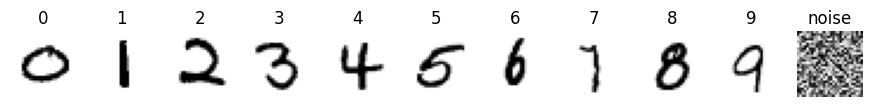

In [3]:
fig, axs = plt.subplots(1, 11, figsize=(11, 1.4))
for j, a in enumerate(axs[:10]):
    i = int(np.flatnonzero(y5 == j)[0])
    a.imshow(np.asarray(X5[i]).reshape(28, 28), cmap="gray_r"); a.set_title(f"{j}", fontsize=12)
noise = jax.random.uniform(section_key(2), (784,))
axs[10].imshow(np.asarray(noise).reshape(28, 28), cmap="gray_r"); axs[10].set_title("noise", fontsize=12)
for a in axs: a.axis("off")
plt.show()

## 2. Principal component analysis

PCA is a **linear** projection. The data are $n$ samples $\mathbf x_1,\dots,\mathbf x_n\in\mathbb R^D$ with mean $\bar{\mathbf x}=\frac1n\sum_i\mathbf x_i$. We write $x_{ij}$ for feature $j$ (pixel $j$) of sample $i$. The **covariance matrix** of the features is the $D\times D$ matrix

$$C_{jl}=\frac1n\sum_{i=1}^{n}(x_{ij}-\bar x_j)(x_{il}-\bar x_l),\qquad C=\frac1n X_c^{\top}X_c ,$$

with $X_c$ the $n\times D$ matrix of centred samples. $C_{jj}$ is the variance of pixel $j$; $C_{jl}$ says how pixels $j$ and $l$ vary together.

### 2.1 Variance maximisation

To find the directions that describe the data best, project every centred sample on a unit vector $\mathbf u$: $w_i=\mathbf u^{\top}(\mathbf x_i-\bar{\mathbf x})$. The variance of the projections is

$$\mathrm{Var}(w)=\frac1n\sum_i w_i^2=\frac1n\sum_i \mathbf u^{\top}(\mathbf x_i-\bar{\mathbf x})(\mathbf x_i-\bar{\mathbf x})^{\top}\mathbf u=\mathbf u^{\top}C\,\mathbf u .$$

We look for the direction of **largest** variance: maximise $\mathbf u^{\top}C\mathbf u$ subject to $\mathbf u^{\top}\mathbf u=1$. With a Lagrange multiplier $\sigma^2$,

$$
\begin{aligned}
\frac{\partial}{\partial\mathbf u}\Big[\mathbf u^{\top}C\mathbf u-\sigma^2(\mathbf u^{\top}\mathbf u-1)\Big]&=2C\mathbf u-2\sigma^2\mathbf u=0\\
\Longrightarrow\quad C\mathbf u&=\sigma^2\mathbf u .
\end{aligned}
$$

The stationary directions are the eigenvectors of $C$, and at an eigenvector the variance is $\mathbf u^{\top}C\mathbf u=\sigma^2$, the eigenvalue. So the best direction is the eigenvector with the largest eigenvalue. Repeating the argument with the extra constraint that $\mathbf u$ is orthogonal to the directions already found gives the next eigenvectors in order.

$C$ is symmetric and positive semi-definite, so it has $D$ orthonormal eigenvectors $C\boldsymbol\lambda_l=\sigma_l^2\boldsymbol\lambda_l$ with $\sigma_1^2\ge\sigma_2^2\ge\dots\ge\sigma_D^2\ge 0$. The unit vector $\boldsymbol\lambda_l$ is the $l$-th **principal direction**, and the eigenvalue $\sigma_l^2$ is the variance of the data along it. The leading $k$ directions are the **principal components**; we collect them as the columns of the $D\times k$ matrix $\Lambda_k=(\boldsymbol\lambda_1,\dots,\boldsymbol\lambda_k)$.

A sample becomes a point of the new space as follows. Take it centred, $\mathbf x_i\to\mathbf x_i-\bar{\mathbf x}$; its coordinate along the $l$-th principal direction is the length of its projection on $\boldsymbol\lambda_l$,

$$w_i^{(l)}=\boldsymbol\lambda_l^{\top}\mathbf x_i,\qquad l=1,\dots,k,$$

and the $k$ coordinates form the new representation of $\mathbf x_i$,

$$\mathbf w_i=\big[w_i^{(1)},\dots,w_i^{(k)}\big]^{\top}=\Lambda_k^{\top}\mathbf x_i\in\mathbb R^{k}.$$

For $k=2$, $\mathbf w_i$ is the point we plot in the plane; for MNIST the map takes $\mathbf x_i\in\mathbb R^{784}$ to $\mathbf w_i\in\mathbb R^{2}$. The map is linear and fixed once $\bar{\mathbf x}$ and $\Lambda_k$ have been fitted, so it applies to new samples as well. The fraction of the variance it keeps is

$$\frac{\sum_{l\le k}\sigma_l^2}{\sum_{l\le D}\sigma_l^2}.$$

The same subspace also minimises the mean squared **reconstruction** error $\frac1n\sum_i\lVert\mathbf x_i-\bar{\mathbf x}-\Lambda_k\mathbf w_i\rVert^2=\sum_{l>k}\sigma_l^2$ (here $\mathbf x_i$ is the uncentred sample again): keeping the largest eigenvalues throws away the least.

### 2.2 Relation to the singular value decomposition

The covariance matrix need not be formed explicitly. Write the centred data matrix through its singular value decomposition (SVD), $X_c=USV^{\top}$. Then $C=\frac1n VS^2V^{\top}$: the right singular vectors (the columns of $V$) are the principal directions $\boldsymbol\lambda_l$, and $\sigma_l^2=s_l^2/n$. Both routes are used below.

Two conventions must be fixed before results from different programs can be compared. scikit-learn divides by $n-1$ instead of $n$; this rescales all eigenvalues by the same factor and changes neither the eigenvectors nor the fractions of variance. The sign of each eigenvector is arbitrary; we fix it so that its largest entry (in absolute value) is positive.

### 2.3 PCA implementation in JAX

The function `pca` below is decorated with `@jax.jit`. The first call traces it and compiles it for the given array shape; the next call with the same shape reuses the compiled code. `jnp.linalg.eigh` diagonalises a symmetric matrix and returns the eigenvalues in **increasing** order, so we reverse them.

In [4]:
@jax.jit
def covariance(X):
    xbar = X.mean(axis=0)
    Xc = X - xbar
    return xbar, Xc.T @ Xc / X.shape[0]

def fix_signs(V):
    # make the largest-|entry| of every column positive (the sign of an eigenvector is arbitrary)
    idx = jnp.argmax(jnp.abs(V), axis=0)
    return V * jnp.sign(V[idx, jnp.arange(V.shape[1])])

@jax.jit
def pca(X):
    # mean, eigenvalues (largest first) and eigenvectors (columns) of the covariance matrix
    xbar, C = covariance(X)
    lam, V = jnp.linalg.eigh(C)
    return xbar, lam[::-1], fix_signs(V[:, ::-1])

We apply it first to a case small enough to see: a two-dimensional cloud of 400 correlated Gaussian points (`jax.random.multivariate_normal` takes a key, a mean and a covariance). The first principal axis should point along the long direction of the cloud.

The same cell tests the variance-maximisation argument numerically: we compute $\mathrm{Var}(w)=\mathbf u(\theta)^{\top}C\,\mathbf u(\theta)$ for 721 unit vectors $\mathbf u(\theta)=(\cos\theta,\sin\theta)$. The function `var_along` is written for **one** angle; `jax.vmap(var_along)` evaluates it for the whole array of angles at once (it adds a batch dimension to every operation, instead of a Python loop). The largest variance over all angles must equal $\sigma_1^2$, and it must occur at the angle of $\boldsymbol\lambda_1$; the printout and the second plot show both.

eigenvalues sigma_l^2: [3.56 0.25] | fraction of the variance: [0.934, 0.066]


largest variance over the angles: 3.5604 at theta = 0.537 | sigma_1^2 = 3.5604, direction of lambda_1: theta = 0.535


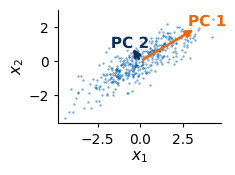

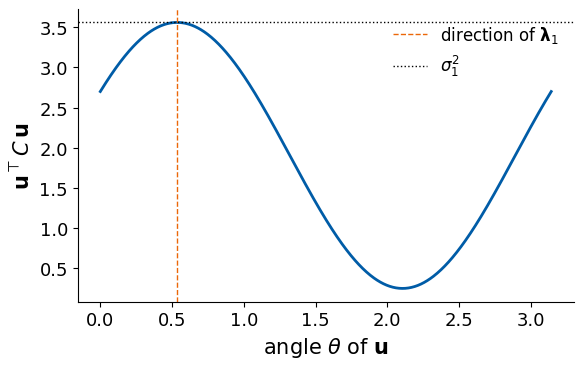

In [5]:
pts = jax.random.multivariate_normal(section_key(3), jnp.zeros(2), jnp.array([[3.0, 1.6], [1.6, 1.2]]), (400,))
xbar_t, lam_t, V_t = pca(pts)
ratio_t = lam_t / lam_t.sum()
nums["pca_toy_var"] = [round(float(r), 3) for r in ratio_t]
print("eigenvalues sigma_l^2:", np.round(np.asarray(lam_t), 3), "| fraction of the variance:", nums["pca_toy_var"])

_, C_t = covariance(pts)
def var_along(theta):
    u = jnp.array([jnp.cos(theta), jnp.sin(theta)])
    return u @ C_t @ u
thetas = jnp.linspace(0, jnp.pi, 721)
var_theta = jax.vmap(var_along)(thetas)
theta_pc1 = jnp.arctan2(V_t[1, 0], V_t[0, 0]) % jnp.pi
print(f"largest variance over the angles: {float(var_theta.max()):.4f} at theta = {float(thetas[jnp.argmax(var_theta)]):.3f}"
      f" | sigma_1^2 = {float(lam_t[0]):.4f}, direction of lambda_1: theta = {float(theta_pc1):.3f}")

# figure for the slides: the cloud and its principal axes
P_ = np.asarray(pts - xbar_t)
with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(2.1, 1.8))
    ax.scatter(P_[:, 0], P_[:, 1], s=3, color=blue, alpha=0.5, lw=0)
    for a_, c, name in zip(range(2), [orange, navy], ["PC 1", "PC 2"]):
        v = np.asarray(V_t[:, a_]); L_ = float(lam_t[a_])
        ax.annotate("", xy=2 * np.sqrt(L_) * v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=1.8))
        ax.text(*(2.4 * np.sqrt(L_) * v), name, color=c, fontsize=11, ha="center", va="center", weight="bold", path_effects=OUTLINE)
    ax.set_aspect("equal"); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); clean(ax)
    save("gen_pca_toy.png"); plt.show()

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(np.asarray(thetas), np.asarray(var_theta), color=blue)
ax.axvline(float(theta_pc1), color=orange, ls="--", lw=1, label=r"direction of $\boldsymbol{\lambda}_1$")
ax.axhline(float(lam_t[0]), color="k", ls=":", lw=1, label=r"$\sigma_1^2$")
ax.set_xlabel(r"angle $\theta$ of $\mathbf{u}$"); ax.set_ylabel(r"$\mathbf{u}^\top C\,\mathbf{u}$"); ax.legend(frameon=False); clean(ax)
plt.show()

### 2.4 PCA on MNIST

The same computation on the 60 000 training images: $C$ is $784\times784$, and its leading eigenvectors, the principal directions $\boldsymbol\lambda_l$, are themselves $28\times28$ images (red and blue: positive and negative weights). We then compute the same eigenvalues a second way, from the SVD of the centred $60000\times784$ data matrix, and compare.

variance kept by 2, 3, 10, 50 components: [0.168, 0.23, 0.488, 0.825] | components needed for 90%: 87


largest relative difference of the first 50 eigenvalues (eigh vs SVD): 2.4e-05


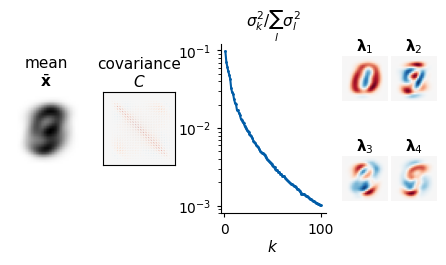

In [6]:
xbar, lam, V = pca(Xtr)
_, C = covariance(Xtr)
frac = jnp.cumsum(lam) / lam.sum()                 # fraction of the variance kept by the first k components
nums["mnist_pca_var2"]  = float(frac[1])
nums["mnist_pca_var3"]  = float(frac[2])
nums["mnist_pca_var10"] = float(frac[9])
nums["mnist_pca_var50"] = float(frac[49])
nums["mnist_pca_frac_2_10_50"] = [round(float(frac[m - 1]), 3) for m in (2, 10, 50)]
nums["mnist_pca_k_for_90"] = int(jnp.searchsorted(frac, 0.90) + 1)
print("variance kept by 2, 3, 10, 50 components:", [round(float(frac[m - 1]), 3) for m in (2, 3, 10, 50)],
      "| components needed for 90%:", nums["mnist_pca_k_for_90"])

# the same eigenvalues from the SVD of the centred data
s = jnp.linalg.svd(Xtr - xbar, compute_uv=False)
lam_svd = s ** 2 / Xtr.shape[0]
print("largest relative difference of the first 50 eigenvalues (eigh vs SVD):",
      f"{float(jnp.max(jnp.abs(lam_svd[:50] - lam[:50]) / lam[:50])):.1e}")

lam_np, V_np, C_np = np.asarray(lam), np.asarray(V), np.asarray(C)
with plt.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.2))
    gs = fig.add_gridspec(2, 7, width_ratios=[1, 0.2, 1, 0.55, 1.45, 0.15, 1.3], wspace=0.05, hspace=0.45)
    a = fig.add_subplot(gs[:, 0]); a.imshow(np.asarray(xbar).reshape(28, 28), cmap="gray_r")
    a.set_title("mean\n" + r"$\bar{\mathbf{x}}$"); a.axis("off")
    a = fig.add_subplot(gs[:, 2]); vm = np.abs(C_np).max(); a.imshow(C_np, cmap="RdBu_r", vmin=-vm, vmax=vm)
    a.set_title("covariance\n" + r"$C$"); a.set_xticks([]); a.set_yticks([])
    a = fig.add_subplot(gs[:, 4]); a.semilogy(np.arange(1, 101), lam_np[:100] / lam_np.sum(), ".-", color=blue, ms=2)
    a.set_title(r"$\sigma_k^2/\sum_l\sigma_l^2$"); a.set_xlabel("$k$"); clean(a)
    gv = gs[:, 6].subgridspec(2, 2, wspace=0.08, hspace=0.45)
    for j in range(4):
        a = fig.add_subplot(gv[j // 2, j % 2]); w = V_np[:, j]; m = np.abs(w).max()
        a.imshow(w.reshape(28, 28), cmap="RdBu_r", vmin=-m, vmax=m); a.set_title(rf"$\boldsymbol{{\lambda}}_{j+1}$", pad=2); a.axis("off")
    save("gen_pca_mnist_steps.png"); plt.show()

The eigenvalues fall quickly: two components keep about a sixth of the variance, and the number of components needed for 90% is printed above. The two routes, eigendecomposition of $C$ and SVD of $X_c$, give the same eigenvalues to float32 precision.

### 2.5 PCA with scikit-learn

In scikit-learn every method is an *estimator* object. Its parameters are set when it is created, `PCA(n_components=50)`; the method `fit(X)` learns from the data and stores the results as attributes with a trailing underscore: the mean image `mean_`, the principal components as the rows of `components_`, their variances `explained_variance_` and the fractions `explained_variance_ratio_`. The method `transform(X)` then projects any data, the training set or new samples, on the learned components (it subtracts `mean_` first), `fit_transform(X)` does both steps at once, and `inverse_transform(W)` maps projections back to pixels, $\bar{\mathbf x}+\Lambda_k\mathbf w$. With `svd_solver="full"` the components come from a complete SVD of the centred data, the same computation as our second route; scikit-learn fixes the signs with the same convention as we do (largest entry of each component positive).

Since both programs solve the same eigenproblem, the results must agree to float32 precision, and the cell asserts it: the fractions of variance, the components (compared through the cosine of the angle between our $\boldsymbol\lambda_l$ and scikit-learn's), and the projections of the 5000 test images. The variances themselves differ by the factor $n/(n-1)$ of the two conventions.

In [7]:
from sklearn.decomposition import PCA

t = time.time()
sk_pca = PCA(n_components=50, svd_solver="full").fit(np.asarray(Xtr))
print(f"scikit-learn PCA of 60000 x 784: {time.time() - t:.1f} s")

ratio_jax = np.asarray(lam[:50] / lam.sum())
ratio_sk = sk_pca.explained_variance_ratio_
cos_v = np.sum(np.asarray(V[:, :50]).T * sk_pca.components_, axis=1)   # cosine between lambda_l (ours) and component l (sklearn)
n = Xtr.shape[0]
print("fraction of variance, first 5 components:")
print("  JAX         ", np.round(ratio_jax[:5], 5))
print("  scikit-learn", np.round(ratio_sk[:5], 5))
print(f"largest relative difference over 50 components: {np.max(np.abs(ratio_sk - ratio_jax) / ratio_jax):.1e}")
print(f"explained_variance_ / sigma_1^2 for the first component: {sk_pca.explained_variance_[0] / float(lam[0]):.6f}"
      f"  (n/(n-1) = {n / (n - 1):.6f})")
print(f"cosine between the components: min over the first 10 {cos_v[:10].min():.6f}, min over 50 {cos_v.min():.6f}")

Z_sk = sk_pca.transform(np.asarray(X5))[:, :10]
Z_jax = np.asarray((X5 - xbar) @ V[:, :10])
print(f"projections of the 5000 test images on 10 components: largest |difference| {np.abs(Z_sk - Z_jax).max():.1e}"
      f" (typical |w| {np.abs(Z_jax).mean():.2f})")

assert np.allclose(ratio_sk, ratio_jax, rtol=1e-3)
assert cos_v[:10].min() > 0.9999                       # same components, same signs
assert np.abs(Z_sk - Z_jax).max() < 1e-2 * np.abs(Z_jax).mean()

scikit-learn PCA of 60000 x 784: 4.3 s


fraction of variance, first 5 components:
  JAX          [0.09705 0.07096 0.06169 0.05389 0.04869]
  scikit-learn [0.09705 0.07096 0.06169 0.05389 0.04869]
largest relative difference over 50 components: 1.7e-05
explained_variance_ / sigma_1^2 for the first component: 1.000021  (n/(n-1) = 1.000017)
cosine between the components: min over the first 10 0.999999, min over 50 0.999999


projections of the 5000 test images on 10 components: largest |difference| 7.6e-04 (typical |w| 1.26)


The fractions of variance agree to float32 precision, and so do the components and the projections; with the common sign convention even the signs coincide. Beyond the first few components the eigenvalues lie closer together, and a small rounding difference can rotate two neighbouring eigenvectors slightly into each other; the minimum cosine over all 50 components, printed above, shows how small this effect is here.

### 2.6 Reconstruction from a few components

An image is rebuilt from its first $k$ projections as $\hat{\mathbf x}=\bar{\mathbf x}+\Lambda_k\mathbf w=\bar{\mathbf x}+\sum_{l\le k}w^{(l)}\boldsymbol\lambda_l$. With all 784 components the reconstruction is exact; with few components only the coarse shape survives. The column titles give the number of components. The printout compares, for each number of components $k$, the mean squared reconstruction error per pixel on the 5000 test images with $\frac1{784}\sum_{l>k}\sigma_l^2$; the two agree exactly on the training data and closely on the test data.

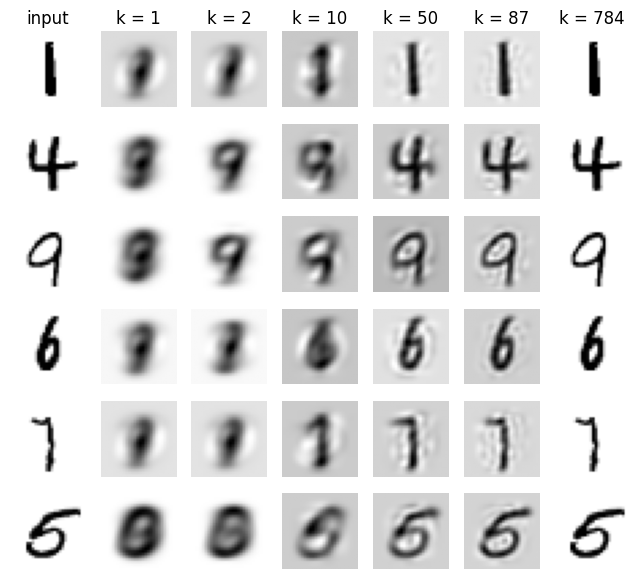

k =   1: test MSE per pixel 0.06078 | sum of discarded sigma_l^2 / 784: 0.06072


k =   2: test MSE per pixel 0.05576 | sum of discarded sigma_l^2 / 784: 0.05595


k =  10: test MSE per pixel 0.03422 | sum of discarded sigma_l^2 / 784: 0.03442
k =  50: test MSE per pixel 0.01157 | sum of discarded sigma_l^2 / 784: 0.01179


k =  87: test MSE per pixel 0.00661 | sum of discarded sigma_l^2 / 784: 0.00672
k = 784: test MSE per pixel 0.00000 | sum of discarded sigma_l^2 / 784: 0.00000


In [8]:
ms = [1, 2, 10, 50, nums["mnist_pca_k_for_90"], 784]
show = X5[:6]
fig, axs = plt.subplots(len(show), len(ms) + 1, figsize=(8, 7))
for r in range(len(show)):
    axs[r, 0].imshow(np.asarray(show[r]).reshape(28, 28), cmap="gray_r")
    for c, m in enumerate(ms):
        Vm = V[:, :m]
        rec = xbar + ((show[r] - xbar) @ Vm) @ Vm.T
        axs[r, c + 1].imshow(np.asarray(rec).reshape(28, 28), cmap="gray_r")
axs[0, 0].set_title("input", fontsize=12)
for c, m in enumerate(ms): axs[0, c + 1].set_title(f"k = {m}", fontsize=12)
for a in axs.ravel(): a.axis("off")
plt.show()
for m in ms:
    Vm = V[:, :m]
    err = jnp.mean((X5 - xbar - ((X5 - xbar) @ Vm) @ Vm.T) ** 2)
    print(f"k = {m:3d}: test MSE per pixel {float(err):.5f} | sum of discarded sigma_l^2 / 784: {float(lam[m:].sum() / 784):.5f}")

### 2.7 Projection on the first components

To see whether the digits form groups in the PCA coordinates, we project the 5000 test images on the 50 leading components and plot the first two coordinates $w_i^{(1)}$, $w_i^{(2)}$, called PC 1 and PC 2 in the figures. The left panel shows what PCA sees, points without labels; the right panel colours the same points by the true digit. Look for digits that occupy their own region and for digits that overlap.

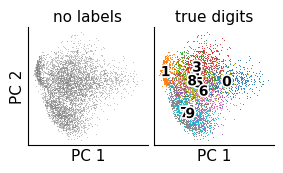

{'mnist_pca_var2': 0.168, 'mnist_pca_var3': 0.23, 'mnist_pca_var50': 0.825}
[  23.1 s] PCA done


In [9]:
Z = (X5 - xbar) @ V[:, :50]                        # 5000 x 50: the input of t-SNE and k-means below
Zn = np.asarray(Z)
with plt.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(2.7, 1.6))
    axs[0].scatter(Zn[:, 0], Zn[:, 1], s=0.6, color="grey", alpha=0.5, lw=0)
    axs[0].set_title("no labels")
    for d in range(10):
        m = y5 == d; axs[1].scatter(Zn[m, 0], Zn[m, 1], s=0.6, color=cmap(d), lw=0)
    for d in range(10):
        axs[1].text(*np.median(Zn[y5 == d, :2], 0), str(d), fontsize=10, weight="bold", ha="center", va="center", path_effects=OUTLINE)
    axs[1].set_title("true digits")
    for a in axs: a.set_xlabel("PC 1"); a.set_xticks([]); a.set_yticks([]); clean(a)
    axs[0].set_ylabel("PC 2")
    plt.tight_layout(pad=0.2, w_pad=0.4); save("gen_pca_mnist.png"); plt.show()
print({k: round(nums[k], 3) for k in ["mnist_pca_var2", "mnist_pca_var3", "mnist_pca_var50"]})
log("PCA done")

### 2.8 Three components

Two components keep only about a sixth of the variance, so a third axis may separate digits that overlap in the plane. The projection on the first three principal components, from two viewing angles:

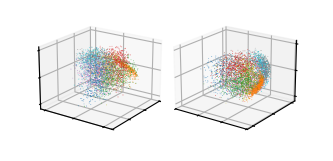

variance kept by 3 components: 0.23


In [10]:
with plt.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(2.7, 1.6))
    for k_, (elev, azim) in enumerate([(20, 35), (20, 125)]):
        a = fig.add_axes([k_ * 0.5, 0.0, 0.5, 1.0], projection="3d")
        for dgt in range(10):
            m = y5 == dgt
            a.scatter(Zn[m, 0], Zn[m, 1], Zn[m, 2], s=0.4, color=cmap(dgt), lw=0)
        a.view_init(elev=elev, azim=azim)
        a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
    save("gen_pca_mnist_3d.png"); plt.show()
print("variance kept by 3 components:", round(nums["mnist_pca_var3"], 3))

Some digits occupy their own region of these plots, while many others overlap: a linear projection to a few dimensions does not separate all ten digits. This is the motivation for the non-linear map of the next section.

#### Exercises

* Plot PC 1 against PC 3, or PC 2 against PC 3. Which digits separate along which component? Compare with the images of the principal directions $\boldsymbol\lambda_l$.
* Run PCA on the images of a single digit (e.g. `Xtr[ytr == 1]`). What do the first eigenvectors describe now (slant, width, ...)?
* Standardise every pixel (divide by its standard deviation, skipping pixels that are always zero) before PCA, i.e. diagonalise the correlation matrix. How does the fraction of variance kept by 50 components change, and why is this not a good idea for images?

## 3. t-SNE

PCA keeps the directions of largest variance, but a linear projection to 2D squeezes curved structure together. t-SNE (van der Maaten & Hinton, J. Mach. Learn. Res. **9**, 2579 (2008), [jmlr.org/papers/v9/vandermaaten08a](https://jmlr.org/papers/v9/vandermaaten08a.html)) asks for something different: **points that are neighbours in $\mathbb R^{D}$ should be neighbours in the map.** To make this precise, t-SNE turns distances into probabilities of being neighbours, once in the data and once in the map, and moves the map points until the two sets of probabilities agree.

In the data, around each point $\mathbf x_i$ put a Gaussian of width $\sigma_i$ and turn the squared distances $d_{ij}^2=\lVert\mathbf x_i-\mathbf x_j\rVert^2$ into a probability over the $n-1$ other points:

$$p_{j|i}=\frac{\exp(-d_{ij}^2/2\sigma_i^2)}{\sum_{l\ne i}\exp(-d_{il}^2/2\sigma_i^2)},\qquad p_{i|i}=0,\qquad p_{ij}=\frac{p_{j|i}+p_{i|j}}{2n}.$$

The symmetrised $p_{ij}$ sum to one over all pairs. Each $\sigma_i$ is chosen so that the distribution $P_i=(p_{j|i})_j$ has a prescribed **perplexity**

$$\mathrm{Perp}(P_i)=e^{H(P_i)},\qquad H(P_i)=-\sum_j p_{j|i}\ln p_{j|i},$$

an effective number of neighbours. ($e^{H}$ with the natural logarithm equals $2^{H}$ with $H$ in bits, the form used in the paper.) A point in a dense region gets a small $\sigma_i$, a point in a sparse region a large one.

For the map points $\mathbf y_i\in\mathbb R^{d}$ the similarities use a Student-t kernel with one degree of freedom (a Cauchy distribution):

$$q_{ij}=\frac{\tilde q_{ij}}{\sum_{l\ne m}\tilde q_{lm}},\qquad \tilde q_{ij}=\big(1+\lVert\mathbf y_i-\mathbf y_j\rVert^2\big)^{-1},\qquad q_{ii}=0 .$$

The map points are moved by gradient descent so that $Q$ approaches $P$, measured by the Kullback–Leibler (KL) divergence, which is zero when the two distributions coincide and positive otherwise:

$$\mathcal L(\mathbf y_1,\dots,\mathbf y_n)=\mathrm{KL}(P\,\|\,Q)=\sum_{i\ne j}p_{ij}\ln\frac{p_{ij}}{q_{ij}} .$$

Neighbours placed far apart ($p_{ij}$ large, $q_{ij}$ small) cost a lot; distant points placed close ($p_{ij}$ small) cost little. t-SNE therefore keeps the **local** structure.

The map point $\mathbf y_i\in\mathbb R^{2}$ is the new representation of $\mathbf x_i\in\mathbb R^{D}$, but, unlike the PCA coordinates $\mathbf w_i=\Lambda_k^{\top}\mathbf x_i$, it is not given by a formula: the $\mathbf y_i$ are free parameters, found by minimising $\mathrm{KL}(P\,\|\,Q)$ between the neighbour probabilities $p_{ij}$ (Gaussian, in the input space) and $q_{ij}$ (Student-t, in the map). There is therefore no map for new points, and only the neighbourhoods in the result are meaningful.

For gradient descent we need $\partial\mathcal L/\partial\mathbf y_i$. Write $\mathcal L=\text{const}-\sum_{i\ne j}p_{ij}\ln \tilde q_{ij}+\ln\sum_{l\ne m}\tilde q_{lm}$ (using $\sum p_{ij}=1$) and use $\partial \tilde q_{ij}/\partial\mathbf y_i=-2\tilde q_{ij}^2(\mathbf y_i-\mathbf y_j)$. Both terms combine into

$$\frac{\partial\mathcal L}{\partial\mathbf y_i}=4\sum_{j}\,(p_{ij}-q_{ij})\,\tilde q_{ij}\,(\mathbf y_i-\mathbf y_j) .$$

A pair with $p_{ij}>q_{ij}$ pulls $\mathbf y_i$ towards $\mathbf y_j$ (attraction), a pair with $p_{ij}<q_{ij}$ pushes it away (repulsion).

The reason for a different kernel in the map is the *crowding problem*: in 784 dimensions a point can have many neighbours at similar distances, and in 2D there is no room for all of them. The heavy tail of the Student-t lets moderately distant points sit far apart in the map, which opens gaps between groups. The figure compares the two kernels.

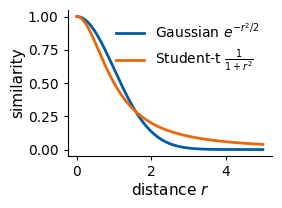

In [11]:
r = np.linspace(0, 5, 300)
with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(2.64, 1.9))
    ax.plot(r, np.exp(-r**2 / 2), color=blue, lw=2, label=r"Gaussian $e^{-r^2/2}$")
    ax.plot(r, 1 / (1 + r**2), color=orange, lw=2, label=r"Student-t $\frac{1}{1+r^2}$")
    ax.set_xlabel("distance $r$"); ax.set_ylabel("similarity"); ax.legend(frameon=False); clean(ax)
    save("gen_tsne_kernels.png"); plt.show()

### 3.1 t-SNE implementation in JAX

The implementation follows the three ingredients of the method: the bandwidths that define $P$, the gradient of the loss, and the optimisation loop.

#### Bandwidths from the perplexity

The bandwidths are a root-finding problem. The entropy $H(P_i)$ decreases monotonically with the *precision* $\beta_i=1/2\sigma_i^2$, so for every point we find $\beta_i$ by bisection until $H(P_i)=\ln(\mathrm{Perp})$. We bisect in $\ln\beta$, because the scale of $\beta$ is unknown, with 64 halvings of the interval $[-23,23]$.

All squared distances are needed at once, and they come from one matrix product by the Gram identity $\lVert\mathbf x_i-\mathbf x_j\rVert^2=\lVert\mathbf x_i\rVert^2+\lVert\mathbf x_j\rVert^2-2\,\mathbf x_i\cdot\mathbf x_j$, instead of an $n\times n\times D$ array of differences; tiny negative values from rounding are clipped to zero. The bisection for one point is a `lax.fori_loop(lo, hi, body, init)`, which runs `body(i, state)` for `i = lo, ..., hi-1` inside the compiled program, with the pair of interval ends as the state. The function `one_row` is written for a single point, and `jax.vmap(one_row)` runs the bisection for all $n$ rows at once, supplying to each its row of distances and its index. Inside, `jax.nn.log_softmax` computes $\ln p_{j|i}$ stably (it subtracts the largest logit before exponentiating), and the point itself is excluded by setting its logit to $-\infty$.

In [12]:
@jax.jit
def sq_dists(X):
    # matrix of squared Euclidean distances, via the Gram matrix (good for many features)
    s = jnp.sum(X * X, axis=1)
    return jnp.maximum(s[:, None] + s[None, :] - 2.0 * X @ X.T, 0.0)

def sq_dists_lowdim(Y):
    # the same for a map with d = 1, 2 or 3 coordinates: exact differences, one coordinate at a time
    # (a Python loop over the d coordinates is unrolled when the function is traced)
    return sum((Y[:, None, a] - Y[None, :, a]) ** 2 for a in range(Y.shape[1]))

def conditional_p(D2, perplexity, n_steps=64):
    # rows p_{j|i} with the prescribed perplexity, and the precisions beta_i = 1 / (2 sigma_i^2)
    n = D2.shape[0]
    target = jnp.log(perplexity)

    def one_row(d_row, i):
        mask = jnp.arange(n) != i                              # exclude j = i

        def p_and_entropy(log_beta):
            logits = jnp.where(mask, -jnp.exp(log_beta) * d_row, -jnp.inf)
            logp = jax.nn.log_softmax(logits)
            p = jnp.exp(logp)
            return p, -jnp.sum(jnp.where(mask, p * logp, 0.0))

        def bisect(_, bounds):
            lo, hi = bounds
            mid = 0.5 * (lo + hi)
            too_wide = p_and_entropy(mid)[1] > target           # entropy too large: increase beta
            return jnp.where(too_wide, mid, lo), jnp.where(too_wide, hi, mid)

        lo, hi = lax.fori_loop(0, n_steps, bisect, (jnp.float32(-23.0), jnp.float32(23.0)))
        log_beta = 0.5 * (lo + hi)
        return p_and_entropy(log_beta)[0], jnp.exp(log_beta)

    return jax.vmap(one_row)(D2, jnp.arange(n))

@jax.jit
def joint_p(X, perplexity):
    # symmetrised p_ij (sums to 1) and the bandwidths sigma_i
    n = X.shape[0]
    Pc, beta = conditional_p(sq_dists(X), perplexity)
    P = (Pc + Pc.T) / (2.0 * n)
    return jnp.maximum(P, 1e-12), jnp.sqrt(1.0 / (2.0 * beta))

We run the search on the 5000 digits in their 50 PCA coordinates, as is common: it is faster, and the noise of the last components is removed. To verify the search we recompute the perplexity of every row from the $p_{j|i}$ that come out of it; all rows should hit the target 30. The histogram then shows how the bandwidths differ between two digits.

binary search for 5000 points: 6.64 s (including compilation)
achieved perplexity: min 30.000, max 30.000 (target 30)
sigma_i: min 0.619, median 1.451, max 2.263


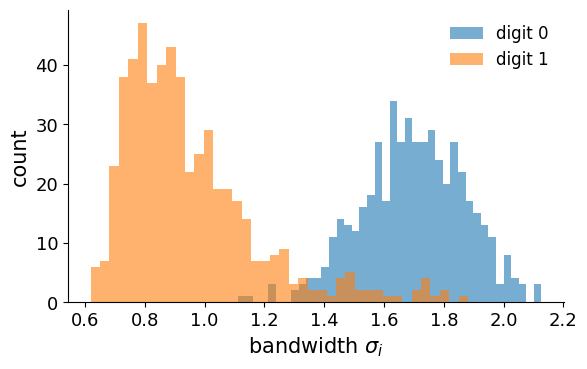

In [13]:
t = time.time()
Pc_chk, beta_chk = jax.jit(conditional_p)(sq_dists(Z), 30.0)
Pc_chk.block_until_ready()
H_chk = -jnp.sum(jnp.where(Pc_chk > 0, Pc_chk * jnp.log(jnp.where(Pc_chk > 0, Pc_chk, 1.0)), 0.0), axis=1)
perp_chk = jnp.exp(H_chk)
sig_chk = np.asarray(jnp.sqrt(1 / (2 * beta_chk)))
print(f"binary search for 5000 points: {time.time() - t:.2f} s (including compilation)")
print(f"achieved perplexity: min {float(perp_chk.min()):.3f}, max {float(perp_chk.max()):.3f} (target 30)")
print(f"sigma_i: min {sig_chk.min():.3f}, median {np.median(sig_chk):.3f}, max {sig_chk.max():.3f}")

fig, ax = plt.subplots(figsize=(6.4, 3.8))
for d in [0, 1]:
    ax.hist(sig_chk[y5 == d], bins=40, alpha=0.6, color=cmap(d), label=f"digit {d}")
ax.set_xlabel(r"bandwidth $\sigma_i$"); ax.set_ylabel("count"); ax.legend(frameon=False); clean(ax)
plt.show()

The 1s are simple strokes that lie close to each other; at the same perplexity they get smaller bandwidths than the 0s. This is how $\sigma_i$ adapts to the local density.

#### Gradient of the loss

The second ingredient is the gradient formula derived above. A derivation of this length is easy to get wrong by a sign or a factor of 2, and JAX offers an independent route: `jax.grad(f)` returns a new function that computes $\partial f/\partial(\text{first argument})$ by reverse-mode automatic differentiation of the code of `f`. We therefore implement both the formula (`tsne_grad_kl`) and the loss written directly from its definition (`kl_loss`), and compare the analytic gradient with `jax.grad(kl_loss)` on 300 points. Agreement to float32 precision confirms the derivation.

The factor `exag` multiplies $P$ during the first iterations (*early exaggeration*, explained below); it is 1 for the plain gradient.

In [14]:
def tsne_grad_kl(P, Y, exag):
    # analytic gradient of KL(exag * P || Q) w.r.t. the map points Y (n x d), and KL(P || Q)
    n = Y.shape[0]
    W = 1.0 / (1.0 + sq_dists_lowdim(Y))
    W = W.at[jnp.diag_indices(n)].set(0.0)                 # w_ii = 0 (functional update of an immutable array)
    Q = jnp.maximum(W / W.sum(), 1e-12)
    PQ = (exag * P - Q) * W
    grad = 4.0 * (PQ.sum(axis=1)[:, None] * Y - PQ @ Y)   # 4 sum_j (p_ij - q_ij) q~_ij (y_i - y_j)
    kl = jnp.sum(P * jnp.log(P / Q))
    return grad, kl

def kl_loss(Y, P):
    # the loss alone, written directly from its definition, for jax.grad
    n = Y.shape[0]
    off = 1.0 - jnp.eye(n)
    W = off / (1.0 + sq_dists_lowdim(Y))
    Q = W / W.sum()
    return jnp.sum(off * P * jnp.log(P / jnp.where(off > 0, Q, 1.0)))

P_small, _ = joint_p(Z[:300], 30.0)
Y_small = jax.random.normal(section_key(4), (300, 2))
g_hand, kl_hand = tsne_grad_kl(P_small, Y_small, 1.0)
g_auto = jax.grad(kl_loss)(Y_small, P_small)
print(f"KL = {float(kl_hand):.5f} (formula) vs {float(kl_loss(Y_small, P_small)):.5f} (definition)")
print(f"largest |difference| of the gradients: {float(jnp.max(jnp.abs(g_hand - g_auto))):.2e}"
      f" (largest |gradient| entry: {float(jnp.max(jnp.abs(g_auto))):.2e})")

KL = 2.41138 (formula) vs 2.41138 (definition)
largest |difference| of the gradients: 1.16e-09 (largest |gradient| entry: 3.73e-03)


#### Optimisation

Plain gradient descent on the KL loss works poorly, and the standard t-SNE optimiser (van der Maaten & Hinton 2008; the same choices as scikit-learn) adds three ingredients. The first is momentum, $\Delta\mathbf y^{(t)}=\mu\,\Delta\mathbf y^{(t-1)}-\eta\,\mathbf g^{(t)}\odot\nabla\mathcal L$, with $\mu=0.5$ for the first 250 iterations and $0.8$ afterwards. The second is early exaggeration: for the first 250 iterations $P$ is multiplied by 12, the attractions dominate, and the clusters form while the map is still small and points can move freely. The third are adaptive gains $\mathbf g$, one per coordinate, increased by $0.2$ when the gradient changes sign with respect to the last update and multiplied by $0.8$ when it keeps its sign (minimum 0.01). The learning rate is $\eta=\max(n/(4\cdot12),\,50)$, the rule behind scikit-learn's `learning_rate="auto"`. The map starts from the first $d$ principal components of the data, scaled to a standard deviation of $10^{-4}$, which makes the result deterministic; with `init="random"` a key is required instead.

The loop itself is a `lax.scan(step, carry, xs)`, compiled once: it calls `step(carry, x)` for every `x` in `xs`, passes the new `carry` on, and stacks the second output of `step` over all iterations. Here the carry is (map, last update, gains), `xs` is the iteration counter, and the stacked output is the KL loss after every iteration. Inside a compiled function a Python `if` on a traced value is not allowed; `jnp.where(it < n_exag, ...)` selects the exaggeration and the momentum instead.

In [15]:
@partial(jax.jit, static_argnames=("n_iter", "n_exag"))
def tsne_optimise(P, Y0, lr, exaggeration=12.0, n_iter=1000, n_exag=250):
    def step(carry, it):
        Y, upd, gains = carry
        early = it < n_exag
        grad, kl = tsne_grad_kl(P, Y, jnp.where(early, exaggeration, 1.0))
        gains = jnp.maximum(jnp.where(upd * grad < 0.0, gains + 0.2, gains * 0.8), 0.01)
        upd = jnp.where(early, 0.5, 0.8) * upd - lr * gains * grad
        Y = Y + upd
        return (Y - Y.mean(axis=0), upd, gains), kl
    init = (Y0, jnp.zeros_like(Y0), jnp.ones_like(Y0))
    (Y, _, _), kl_history = lax.scan(step, init, jnp.arange(n_iter))
    return Y, kl_history

def tsne(X, d=2, perplexity=30.0, n_iter=1000, init="pca", key=None, exaggeration=12.0, n_exag=250):
    # exact t-SNE: returns the map (n x d), the KL loss per iteration and the bandwidths sigma_i
    X = jnp.asarray(X, jnp.float32)
    n = X.shape[0]
    P, sigma = joint_p(X, perplexity)
    if init == "pca":
        _, _, Vx = pca(X)
        Y0 = (X - X.mean(axis=0)) @ Vx[:, :d]
        Y0 = Y0 / jnp.std(Y0[:, 0]) * 1e-4
    else:
        Y0 = 1e-4 * jax.random.normal(key, (n, d))
    lr = max(n / exaggeration / 4.0, 50.0)
    Y, kl = tsne_optimise(P, Y0, lr, exaggeration, n_iter=n_iter, n_exag=n_exag)
    return Y, kl, sigma

### 3.2 Example: three hidden groups

Before the digits, an example small enough to understand completely. 450 points in $\mathbb R^3$ form **three groups** (uniform balls of radius 1 whose centres lie on a diagonal,
2.4 apart), but we do not know it: the data come without colours. Seen along the diagonal the groups hide behind each other, and along
every coordinate axis their values overlap, so no single coordinate reveals them. (From another angle the eye would find them in 3D;
in 100 dimensions there is no angle to look from.) t-SNE with $d=1$ gives each point one number $y_i$,
its position on a line, keeping close points close. On that line the three groups separate.

t-SNE of 450 points to d = 1: 3.6 s (including compilation)
two largest gaps on the line: [13.3 14.3]  (median gap 0.10)
each group found on the line contains points of a single true group: purity 1.000


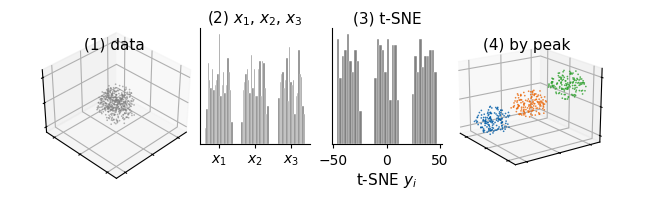

In [16]:
def ball(key, n, r=1.0):
    k1, k2 = jax.random.split(key)
    v = jax.random.normal(k1, (n, 3)); v = v / jnp.linalg.norm(v, axis=1, keepdims=True)
    return v * r * jax.random.uniform(k2, (n, 1)) ** (1 / 3)

diag = jnp.ones(3) / jnp.sqrt(3.0)
keys3 = jax.random.split(section_key(5), 3)
X3 = jnp.concatenate([ball(keys3[k], 150) + (k - 1) * 2.4 * diag for k in range(3)])
g3 = np.repeat(np.arange(3), 150)                     # the true groups: used only to check the result

t = time.time()
Y1, kl1, _ = tsne(X3, d=1, perplexity=30.0)
Y1 = np.asarray(Y1[:, 0]); print(f"t-SNE of 450 points to d = 1: {time.time() - t:.1f} s (including compilation)")

# groups found on the line: cut at the two largest gaps between neighbouring points
order1 = np.argsort(Y1); gaps = np.diff(Y1[order1])
cuts = np.sort(np.argsort(gaps)[-2:])
found = np.zeros(len(Y1), int)
for c in cuts: found[order1[c + 1:]] += 1
purity = np.mean([np.bincount(g3[found == f], minlength=3).max() / (found == f).sum() for f in range(3)])
print(f"two largest gaps on the line: {np.round(np.sort(gaps)[-2:], 1)}  (median gap {np.median(gaps):.2f})")
print(f"each group found on the line contains points of a single true group: purity {purity:.3f}")
nums["tsne_line_purity"] = round(float(purity), 3)

X3n = np.asarray(X3); cols3 = [blue, orange, green]
with plt.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 1.75))
    a = fig.add_axes([0.0, 0.0, 0.25, 0.86], projection="3d")
    a.scatter(*X3n.T, s=1.5, color="grey", alpha=0.6, lw=0); a.view_init(elev=35.26, azim=45)   # looking along the diagonal (1,1,1)
    a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
    a.set_box_aspect(None, zoom=1.15); a.set_title("(1) data", y=1.0, pad=-2)
    a = fig.add_axes([0.28, 0.2, 0.2, 0.66])
    for ax_i in range(3):
        a.hist(X3n[:, ax_i] + 6.0 * ax_i, bins=20, color="grey", edgecolor="white", lw=0.3)
    a.set_xticks([0, 6.0, 12.0]); a.set_xticklabels(["$x_1$", "$x_2$", "$x_3$"]); a.set_yticks([]); clean(a)
    a.set_title("(2) $x_1$, $x_2$, $x_3$")
    a = fig.add_axes([0.52, 0.2, 0.2, 0.66])
    a.hist(Y1, bins=40, color="grey", edgecolor="white", lw=0.3); a.set_yticks([]); clean(a)
    a.set_xlabel("t-SNE $y_i$"); a.set_title("(3) t-SNE")
    a = fig.add_axes([0.75, 0.0, 0.25, 0.86], projection="3d")
    for f in range(3):
        a.scatter(*X3n[found == f].T, s=1.5, color=cols3[f], alpha=0.8, lw=0)
    a.view_init(elev=18, azim=-35); a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
    a.set_box_aspect(None, zoom=1.15); a.set_title("(4) by peak", y=1.0, pad=-2)
    save("gen_tsne_3d_to_line.png"); plt.show()

The three peaks on the line contain the three true groups exactly (purity printed above). t-SNE kept the **neighbours** of every point,
and that was enough to separate groups that no single coordinate and no 3D view showed clearly. What the line does not keep are the
large distances: the gaps between the peaks are not the distances between the groups in 3D. Only "who is next to whom" is meaningful in a
t-SNE map.

### 3.3 t-SNE of the MNIST digits

Now the 5000 digits, again from their 50 PCA coordinates, mapped to the plane. Besides the map, the cell plots the KL loss after every iteration, so that we can watch the three phases of the optimiser at work.

t-SNE of 5000 points, d = 2: 132.6 s (including compilation)
final KL(P||Q): 1.335


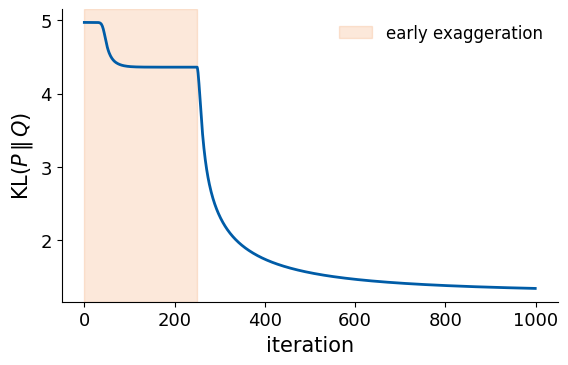

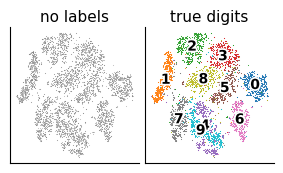

[ 179.9 s] t-SNE 2D done


In [17]:
t = time.time()
E, kl_E, sigma_E = tsne(Z, d=2, perplexity=30.0)
E.block_until_ready(); print(f"t-SNE of 5000 points, d = 2: {time.time() - t:.1f} s (including compilation)")
nums["tsne_mnist_kl_final"] = float(kl_E[-1])
print(f"final KL(P||Q): {nums['tsne_mnist_kl_final']:.3f}")

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(np.asarray(kl_E), color=blue)
ax.axvspan(0, 250, color=orange, alpha=0.15, label="early exaggeration")
ax.set_xlabel("iteration"); ax.set_ylabel(r"KL$(P\,\|\,Q)$"); ax.legend(frameon=False); clean(ax)
plt.show()

En = np.asarray(E)
with plt.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(2.7, 1.6))
    axs[0].scatter(En[:, 0], En[:, 1], s=0.6, color="grey", alpha=0.5, lw=0)
    axs[0].set_title("no labels")
    for d in range(10):
        m = y5 == d; axs[1].scatter(En[m, 0], En[m, 1], s=0.6, color=cmap(d), lw=0)
    for d in range(10):
        axs[1].text(*np.median(En[y5 == d], 0), str(d), fontsize=10, weight="bold", ha="center", va="center", path_effects=OUTLINE)
    axs[1].set_title("true digits")
    for a in axs: a.set_xticks([]); a.set_yticks([]); clean(a)
    plt.tight_layout(pad=0.2, w_pad=0.4); save("gen_tsne_mnist.png"); plt.show()
log("t-SNE 2D done")

The loss is always evaluated with the true $P$. During early exaggeration it changes little: the exaggerated attractions gather the clusters, but the map is still compact. Once the exaggeration is switched off, the clusters spread out, the loss falls quickly, and then it decreases slowly. In the map itself most digits form their own island, in contrast to the PCA projection of Section 2.

### 3.4 t-SNE in three dimensions

The same loss with $\mathbf y_i\in\mathbb R^3$; only `d` changes. A third dimension gives the map more room, so we expect a lower final loss. Two viewing angles of the same map:

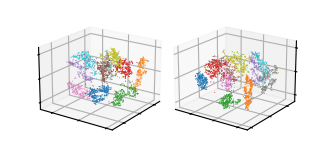

final KL(P||Q): d = 2: 1.335 | d = 3: 1.215
[ 305.6 s] t-SNE 3D done


In [18]:
E3, kl_E3, _ = tsne(Z, d=3, perplexity=30.0)
E3n = np.asarray(E3)
with plt.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(2.7, 1.6))
    for k_, (elev, azim) in enumerate([(20, 35), (20, 125)]):
        a = fig.add_axes([k_ * 0.5, 0.0, 0.5, 1.0], projection="3d")
        for dgt in range(10):
            m = y5 == dgt; a.scatter(E3n[m, 0], E3n[m, 1], E3n[m, 2], s=0.4, color=cmap(dgt), lw=0)
        a.view_init(elev=elev, azim=azim); a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
    save("gen_tsne_mnist_3d.png"); plt.show()
print(f"final KL(P||Q): d = 2: {float(kl_E[-1]):.3f} | d = 3: {float(kl_E3[-1]):.3f}")
log("t-SNE 3D done")

### 3.5 Perplexity

The perplexity is the one parameter of t-SNE that changes the result qualitatively, because it sets how many neighbours each point tries to keep. The figure shows the first 2000 of the same digits with three perplexities. Small values keep only very close neighbours (many small fragments); large values smooth the map.

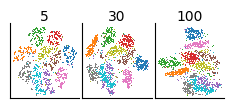

[ 344.8 s] perplexity scan done


In [19]:
Zs, ys = Z[:2000], y5[:2000]
maps_pp = {pp: np.asarray(tsne(Zs, d=2, perplexity=float(pp))[0]) for pp in [5, 30, 100]}
with plt.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(2.2, 0.95))
    for a, (pp, Ep) in zip(axs, maps_pp.items()):
        for dgt in range(10):
            m = ys == dgt; a.scatter(Ep[m, 0], Ep[m, 1], s=0.5, color=cmap(dgt), lw=0)
        a.set_title(f"{pp}", fontsize=10, pad=2); a.set_xticks([]); a.set_yticks([]); clean(a)
    plt.tight_layout(pad=0.2, w_pad=0.2); save("gen_tsne_perplexity.png"); plt.show()
log("perplexity scan done")

### 3.6 Distances on a t-SNE map

The construction of the loss tells us which features of a map carry meaning. The position of a cluster carries none: the loss depends only on distances between map points, so a rotated, mirrored or shifted map is equally good, and another initialisation puts the clusters elsewhere. The separation between clusters carries little: pairs of distant points have $p_{ij}\approx0$ and barely enter the loss, and the Student-t tail pushes groups apart, so a wide gap does not mean very different data. Cluster sizes carry little as well, because $\sigma_i$ adapts to the local density and dense and sparse groups come out of similar size. Inside a cluster, only the nearest neighbours of each point (about as many as the perplexity) are kept, and larger distances are not to scale.

What the map shows reliably is which points are close neighbours. t-SNE places only the points it was given: there is no map for new samples.

### 3.7 t-SNE with scikit-learn

scikit-learn provides t-SNE as `sklearn.manifold.TSNE`. Its main parameters are the ones we met: `n_components` ($d$), `perplexity`, `early_exaggeration` (12), `learning_rate="auto"` (the rule $\max(n/(4\cdot12),50)$), `max_iter` (1000 by default) and `init="pca"`. Since a t-SNE map cannot be applied to new points, the estimator has no `transform`; one calls `fit_transform(X)`, which returns the map, and the final value of the loss is stored in `kl_divergence_`. The default `method="barnes_hut"` differs from our exact computation in two places: $p_{j|i}$ is computed only for the $3\cdot\mathrm{Perp}$ nearest neighbours of each point (all other $p_{j|i}$ are set to zero), and the repulsive part of the gradient is approximated with a Barnes–Hut tree, which groups distant points into cells (L. van der Maaten, J. Mach. Learn. Res. **15**, 3221 (2014), [jmlr.org/papers/v15/vandermaaten14a](https://jmlr.org/papers/v15/vandermaaten14a.html)). This reduces the cost per iteration from $O(n^2)$ to about $O(n\log n)$; `method="exact"` is also available.

Two runs of t-SNE never give the same map: different optimisers, or the same optimiser with a different approximation, end in different local minima, and even equally good maps differ by rotations and reflections. The two maps can therefore not be compared point by point. We compare instead what a t-SNE map is meant to preserve, the neighbours, with three measures. The first is the exact loss $\mathrm{KL}(P\,\|\,Q)$ of both maps, evaluated with our $P$. The second is the **trustworthiness** (J. Venna and S. Kaski, *Neighborhood preservation in nonlinear projection methods: an experimental study*, ICANN 2001, Lecture Notes in Computer Science **2130**, 485 (2001), [doi:10.1007/3-540-44668-0_68](https://doi.org/10.1007/3-540-44668-0_68)), available as `sklearn.manifold.trustworthiness`. With $r(i,j)$ the rank of $\mathbf x_j$ among the neighbours of $\mathbf x_i$ in the data, and $U_i^{k}$ the points that are among the $k$ nearest neighbours of $i$ in the map but not in the data,
$$
T(k)=1-\frac{2}{nk(2n-3k-1)}\sum_{i=1}^{n}\sum_{j\in U_i^{k}}\big(r(i,j)-k\big),
$$
which equals 1 when every map neighbour is also a data neighbour and penalises intruders by how far away they really are. The third uses the labels only for scoring: the fraction of the $k=10$ nearest map neighbours of a point that show the same digit, averaged over all points. For orientation, the same fraction is computed in the 50 PCA coordinates that both maps start from.

scikit-learn t-SNE (Barnes-Hut) of 5000 points: 33.5 s


JAX, exact               : exact KL(P||Q) 1.335 | trustworthiness T(10) 0.9855 | same digit among 10 map neighbours 0.916


scikit-learn, Barnes-Hut : exact KL(P||Q) 1.379 | trustworthiness T(10) 0.9862 | same digit among 10 map neighbours 0.918
50 PCA coordinates       :                                              same digit among 10 neighbours 0.896


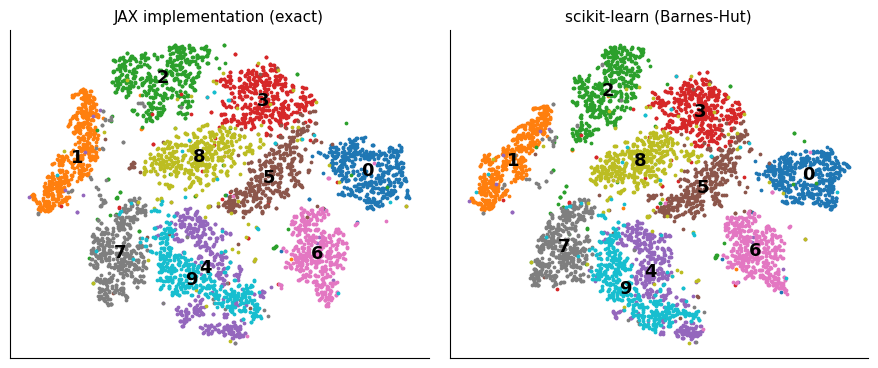

In [20]:
from sklearn.manifold import TSNE, trustworthiness

t = time.time()
E_sk = TSNE(n_components=2, perplexity=30.0, init="pca", learning_rate="auto", random_state=0).fit_transform(Zn)
print(f"scikit-learn t-SNE (Barnes-Hut) of 5000 points: {time.time() - t:.1f} s")

P_E, _ = joint_p(Z, 30.0)                                    # our exact P, the same for both maps
def knn_label_agreement(Y, labels, k=10):
    # mean fraction of the k nearest neighbours (in Y) that carry the same label
    D2 = np.array(sq_dists(jnp.asarray(Y, jnp.float32)))             # a writable copy
    np.fill_diagonal(D2, np.inf)
    nn = np.argpartition(D2, k, axis=1)[:, :k]
    return float(np.mean(labels[nn] == labels[:, None]))

tsne_cmp = {}
for name, Y in [("JAX, exact", En), ("scikit-learn, Barnes-Hut", E_sk)]:
    kl = float(tsne_grad_kl(P_E, jnp.asarray(Y, jnp.float32), 1.0)[1])
    tw = trustworthiness(Zn, Y, n_neighbors=10)
    tsne_cmp[name] = (kl, tw, knn_label_agreement(Y, y5))
    print(f"{name:25s}: exact KL(P||Q) {kl:.3f} | trustworthiness T(10) {tw:.4f} | same digit among 10 map neighbours {tsne_cmp[name][2]:.3f}")
print(f"{'50 PCA coordinates':25s}:                                              same digit among 10 neighbours {knn_label_agreement(Zn, y5):.3f}")
nums["tsne_sklearn_vs_jax"] = {k: [round(v, 4) for v in vals] for k, vals in tsne_cmp.items()}

fig, axs = plt.subplots(1, 2, figsize=(9, 3.9))
for a, Y, title in zip(axs, [En, E_sk], ["JAX implementation (exact)", "scikit-learn (Barnes-Hut)"]):
    for d in range(10):
        m = y5 == d; a.scatter(Y[m, 0], Y[m, 1], s=3, color=cmap(d))
        a.text(*np.median(Y[m], 0), str(d), fontsize=13, weight="bold", ha="center", va="center")
    a.set_title(title, fontsize=11); a.set_xticks([]); a.set_yticks([]); clean(a)
plt.tight_layout(); plt.show()

The two maps look different in detail: the islands sit in other places and may be mirrored, as expected. The three measures, however, are close: both maps keep the neighbours of the data to a similar degree, and the exact loss shows how far the approximate optimiser ends from our exact one. Note also that the fraction of same-digit neighbours is higher in either map than in the 50 PCA coordinates they were computed from, although t-SNE never saw a label: keeping the nearest neighbours and discarding the large distances makes the digit structure easier to see.

#### Exercises

* Rerun `tsne(Z, init="random", key=jax.random.key(1))` and with another key. Which features of the map stay, which change?
* Switch off early exaggeration (`exaggeration=1.0`). How do the final map and the final KL loss change?
* Replace the Student-t kernel by a Gaussian in the map, $\tilde q_{ij}=e^{-\lVert\mathbf y_i-\mathbf y_j\rVert^2}$ (this is *symmetric SNE*, stochastic neighbour embedding, the predecessor of t-SNE). Derive the new gradient, check it with `jax.grad`, and look at the crowding of the clusters.
* Run t-SNE on the raw 784 pixels instead of the 50 PCA components. Is the map different? How long does `joint_p` take?

## 4. Clustering

The maps of Sections 2 and 3 show groups to the eye. Clustering algorithms make this precise: they assign every sample to a group without being told what the groups are.

### 4.1 k-means

k-means splits the samples into $k$ groups $S_1,\dots,S_k$ with centres $\boldsymbol\mu_1,\dots,\boldsymbol\mu_k$ by minimising the total squared distance of the samples to their centres,

$$\mathcal L=\sum_{c=1}^{k}\sum_{i\in S_c}\lVert\mathbf x_i-\boldsymbol\mu_c\rVert^2 .$$

**Lloyd's algorithm** (S. P. Lloyd, IEEE Trans. Inf. Theory **28**, 129 (1982)) alternates two moves until no sample changes cluster:

1. *assign:* every sample joins its nearest centre, $c_i=\arg\min_c\lVert\mathbf x_i-\boldsymbol\mu_c\rVert^2$;
2. *update:* every centre moves to the mean of its samples, $\boldsymbol\mu_c=\frac1{|S_c|}\sum_{i\in S_c}\mathbf x_i$.

Each move can only lower $\mathcal L$: the assignment minimises $\mathcal L$ over the assignments for fixed centres, and the update minimises it over the centres for fixed assignments (the mean is the point with the smallest sum of squared distances, $\partial_{\boldsymbol\mu}\sum_{i\in S_c}\lVert\mathbf x_i-\boldsymbol\mu\rVert^2=0$). There are finitely many partitions, so the algorithm stops, but possibly in a poor local minimum. Two remedies are used together. The first is the k-means++ initialisation (D. Arthur and S. Vassilvitskii, *k-means++: the advantages of careful seeding*, Proc. ACM-SIAM Symposium on Discrete Algorithms (SODA) 2007): the first centre is a random sample, and each next centre is a sample drawn with probability proportional to $D(\mathbf x)^2$, its squared distance to the nearest centre chosen so far, so that the centres start spread out over the data. The second is to run several starts (here 10) and keep the one with the lowest $\mathcal L$.

### 4.2 k-means implementation in JAX

In the implementation, the iteration is a `lax.while_loop(cond, body, state)`, which repeats `body` while `cond(state)` is true; the number of iterations is decided at run time, inside the compiled program. The update step uses a one-hot matrix $H_{ic}=[c_i=c]$: the sums of the samples of each cluster are $H^{\top}X$ and the counts are the column sums of $H$, one matrix product without a loop over clusters (an empty cluster keeps its old centre). The k-means++ draw is `jax.random.choice(key, n, p=...)`, which draws an index with given probabilities, and `jax.vmap` over keys runs the 10 independent starts in parallel. The number of clusters `k` is a `static` argument: it fixes the array shapes, so a new `k` compiles a new program.

In [21]:
def sq_dists_xy(X, M):
    # squared distances between the rows of X (n x D) and of M (k x D)
    return jnp.maximum(jnp.sum(X * X, 1)[:, None] + jnp.sum(M * M, 1)[None, :] - 2.0 * X @ M.T, 0.0)

@jax.jit
def assign(X, mu):
    d2 = sq_dists_xy(X, mu)
    return jnp.argmin(d2, axis=1), jnp.min(d2, axis=1)

@partial(jax.jit, static_argnames="k")
def update_centres(X, labels, mu_old, k):
    H = jax.nn.one_hot(labels, k, dtype=X.dtype)                 # n x k
    counts = H.sum(axis=0)
    sums = H.T @ X
    return jnp.where(counts[:, None] > 0, sums / jnp.maximum(counts, 1.0)[:, None], mu_old)

def kmeans_pp_init(key, X, k):
    n = X.shape[0]
    key, sub = jax.random.split(key)
    first = jax.random.randint(sub, (), 0, n)
    mu = jnp.zeros((k, X.shape[1]), X.dtype).at[0].set(X[first])
    d2 = jnp.sum((X - X[first]) ** 2, axis=1)                    # squared distance to the nearest centre
    def body(c, state):
        mu, d2, key = state
        key, sub = jax.random.split(key)
        idx = jax.random.choice(sub, n, p=d2 / d2.sum())
        return mu.at[c].set(X[idx]), jnp.minimum(d2, jnp.sum((X - X[idx]) ** 2, axis=1)), key
    mu, _, _ = lax.fori_loop(1, k, body, (mu, d2, key))
    return mu

def lloyd(X, mu0, max_iter=300):
    k = mu0.shape[0]
    def cond(state):
        _, _, changed, it = state
        return changed & (it < max_iter)
    def body(state):
        mu, labels, _, it = state
        mu = update_centres(X, labels, mu, k)
        new_labels, _ = assign(X, mu)
        return mu, new_labels, jnp.any(new_labels != labels), it + 1
    labels0, _ = assign(X, mu0)
    mu, labels, _, n_it = lax.while_loop(cond, body, (mu0, labels0, jnp.array(True), jnp.int32(0)))
    return mu, labels, jnp.sum(assign(X, mu)[1]), n_it

@partial(jax.jit, static_argnames=("k", "n_init", "max_iter"))
def kmeans(key, X, k, n_init=10, max_iter=300):
    # best of n_init k-means++ starts: centres, labels, loss L, number of Lloyd iterations
    def one_start(kk):
        return lloyd(X, kmeans_pp_init(kk, X, k), max_iter)
    mus, labels, losses, iters = jax.vmap(one_start)(jax.random.split(key, n_init))
    best = jnp.argmin(losses)
    return mus[best], labels[best], losses[best], iters[best]

### 4.3 Lloyd iterations on a toy example

Three groups of 100 points in 2D. To see the algorithm work, the three centres start badly on purpose: all three inside the same group (lower right). The panels show the start, the first two iterations and the final state; colours are the current assignment, crosses the centres. The printout lists the loss after every iteration; by the argument above it can only decrease.

loss at the start and after each iteration: [9424.  3570.1 2812.3 1103.2  761.3]
iteration 4 changes no assignment: converged


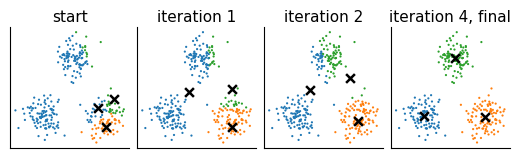

In [22]:
def make_blobs(key, n_per, centres, std):
    centres = jnp.asarray(centres, jnp.float32)
    pts = centres[:, None, :] + std * jax.random.normal(key, (len(centres), n_per, centres.shape[1]))
    return pts.reshape(-1, centres.shape[1]), np.repeat(np.arange(len(centres)), n_per)

Xb, _ = make_blobs(section_key(6), 100, [[-4.0, -2.0], [4.0, -2.0], [0.0, 4.5]], 1.1)
mu = jnp.array([[3.0, -1.0], [4.0, -3.0], [5.0, 0.0]])          # a poor start: all three centres in one group
history = [(mu, assign(Xb, mu)[0])]
losses = [float(jnp.sum(assign(Xb, mu)[1]))]
while True:                                       # one iteration = update, then assign
    mu = update_centres(Xb, history[-1][1], mu, 3)
    lab, d2 = assign(Xb, mu)
    losses.append(float(d2.sum()))
    history.append((mu, lab))
    if bool(jnp.all(lab == history[-2][1])):
        break
nums["kmeans_iter_toy_n_iter"] = len(history) - 1
print("loss at the start and after each iteration:", np.round(losses, 1))
print("iteration", nums["kmeans_iter_toy_n_iter"], "changes no assignment: converged")

panels = [0, 1, 2, len(history) - 1] if len(history) > 4 else list(range(len(history)))
Xbn = np.asarray(Xb)
with plt.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, len(panels), figsize=(5.06, 1.45))
    for a, it in zip(axs, panels):
        mu_, lab_ = history[it]; mu_ = np.asarray(mu_)
        a.scatter(Xbn[:, 0], Xbn[:, 1], s=2.5, c=cmap(np.asarray(lab_)), lw=0)
        a.scatter(mu_[:, 0], mu_[:, 1], marker="x", s=40, color="k", lw=1.8)
        title = "start" if it == 0 else f"iteration {it}"
        if it == len(history) - 1 and it > 0: title += ", final"
        a.set_title(title); a.set_xticks([]); a.set_yticks([]); clean(a)
    plt.tight_layout(pad=0.2, w_pad=0.5); save("gen_kmeans_iterations.png"); plt.show()

The loss falls at every iteration, and after a few iterations the centres have moved from the one group into all three: a bad start is repaired here, but on less clearly separated data it need not be, which is why k-means++ and several starts are used.

### 4.4 Silhouette score

A clustering algorithm always returns clusters, so we need a way to judge them without labels. In a good clustering each sample is close to its own cluster and far from the others (P. J. Rousseeuw, J. Comput. Appl. Math. **20**, 53 (1987)). For a sample $\mathbf x_i$ in cluster $S_c$:

$$a_i=\frac{1}{|S_c|-1}\sum_{j\in S_c,\,j\ne i}\lVert\mathbf x_i-\mathbf x_j\rVert,\qquad b_i=\min_{c'\ne c}\frac{1}{|S_{c'}|}\sum_{j\in S_{c'}}\lVert\mathbf x_i-\mathbf x_j\rVert,\qquad s_i=\frac{b_i-a_i}{\max(a_i,b_i)}\in[-1,1].$$

$s_i\approx1$: well inside its cluster; $s_i\approx0$: on the border between two clusters; $s_i<0$: closer to another cluster. For a cluster with a single sample $s_i=0$ by convention. The mean $\bar s=\frac1n\sum_is_i$ scores the whole clustering.

In JAX all mean distances to all clusters come from one product: with the distance matrix $D_{ij}$ and the one-hot matrix $H$, $(DH)_{ic}$ is the sum of distances from $i$ to the members of $c$.

The sketch shows the two distances for one point.

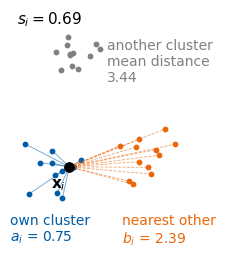

{'a_i': 0.75, 'b_i': 2.39, 's_i': 0.69}


In [23]:
@partial(jax.jit, static_argnames="k")
def silhouette_samples(D, labels, k):
    # s_i for every sample, from the matrix of (not squared) distances D
    n = D.shape[0]
    H = jax.nn.one_hot(labels, k, dtype=D.dtype)
    counts = H.sum(axis=0)
    sums = D @ H                                           # sum of distances from i to each cluster
    own = counts[labels]
    a = sums[jnp.arange(n), labels] / jnp.maximum(own - 1.0, 1.0)
    mean_other = jnp.where((H > 0) | (counts[None, :] == 0), jnp.inf, sums / jnp.maximum(counts, 1.0)[None, :])
    b = mean_other.min(axis=1)
    return jnp.where(own > 1, (b - a) / jnp.maximum(a, b), 0.0)

def silhouette(D, labels, k):
    return float(silhouette_samples(D, labels, k).mean())

k1, k2, k3 = jax.random.split(section_key(8), 3)
own  = np.asarray(jnp.array([0.0, 0.0]) + 0.45 * jax.random.normal(k1, (12, 2)))   # the cluster of point i
near = np.asarray(jnp.array([3.0, 0.3]) + 0.45 * jax.random.normal(k2, (12, 2)))   # the nearest other cluster
far  = np.asarray(jnp.array([0.8, 3.6]) + 0.45 * jax.random.normal(k3, (12, 2)))   # another cluster
xi = np.array([0.6, 0.2]); others = own[1:]
a_i = np.linalg.norm(others - xi, axis=1).mean()
b_near = np.linalg.norm(near - xi, axis=1).mean(); b_far = np.linalg.norm(far - xi, axis=1).mean()
b_i = min(b_near, b_far); s_i = (b_i - a_i) / max(a_i, b_i)
nums["silhouette_sketch"] = {"a_i": round(float(a_i), 2), "b_i": round(float(b_i), 2), "s_i": round(float(s_i), 2)}

with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(2.42, 2.3))
    for q in others: ax.plot([xi[0], q[0]], [xi[1], q[1]], color=blue, lw=0.6, alpha=0.6)
    for q in near:   ax.plot([xi[0], q[0]], [xi[1], q[1]], color=orange, lw=0.6, alpha=0.6, ls="--")
    ax.scatter(*others.T, s=10, color=blue); ax.scatter(*near.T, s=10, color=orange); ax.scatter(*far.T, s=10, color="grey")
    ax.scatter(*xi, s=45, color="k", zorder=5)
    ax.annotate(r"$\mathbf{x}_i$", xi, xytext=(-13, -15), textcoords="offset points", fontsize=11)
    ax.text(-1.2, -1.2, f"own cluster\n$a_i$ = {a_i:.2f}", color=blue, fontsize=10, va="top")
    ax.text(2.2, -1.2, f"nearest other\n$b_i$ = {b_i:.2f}", color=orange, fontsize=10, va="top")
    ax.text(1.75, 4.1, f"another cluster\nmean distance\n{b_far:.2f}", color="grey", fontsize=10, va="top")
    ax.set_title(rf"$s_i = {s_i:.2f}$", loc="left")
    ax.set_aspect("equal"); ax.axis("off")
    save("gen_silhouette_sketch.png"); plt.show()
print(nums["silhouette_sketch"])

### 4.5 Number of clusters

k-means needs $k$ from us, and two common guides help to choose it. The loss $\mathcal L(k)$ always decreases when $k$ grows (more centres, shorter distances), so its minimum is useless; instead one looks for the **elbow**, the $k$ after which it decreases only slowly. The **silhouette** gives a direct criterion: pick the $k$ with the largest $\bar s(k)$.

We test both on data where the right answer is known, four Gaussian groups of 150 points. For every $k=2,\dots,8$ we run k-means (10 starts, keep the lowest loss), record $\mathcal L(k)$ and $\bar s(k)$, and plot both against $k$. The dotted line marks $k=4$, drawn only for comparison.

k:          [2, 3, 4, 5, 6, 7, 8]
loss:       [7275. 3812. 1206. 1084.  965.  847.  753.]
silhouette: [0.477 0.561 0.692 0.599 0.522 0.435 0.346]
largest silhouette at k = 4


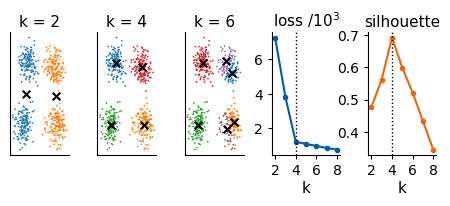

In [24]:
Xk, yk = make_blobs(section_key(9), 150, [[-4.0, -3.0], [-3.0, 3.5], [3.0, 3.0], [3.5, -3.0]], 1.0)
Dk = jnp.sqrt(sq_dists(Xk))
ks4 = list(range(2, 9)); loss4, sil4, fits4 = [], [], {}
for kk in ks4:
    mu_, lab_, L_, _ = kmeans(section_key(10), Xk, kk)
    loss4.append(float(L_)); sil4.append(silhouette(Dk, lab_, kk)); fits4[kk] = (np.asarray(mu_), np.asarray(lab_))
nums["toy4_best_k_silhouette"] = int(ks4[int(np.argmax(sil4))])
nums["toy4_silhouette"] = [round(s_, 3) for s_ in sil4]
print("k:         ", ks4); print("loss:      ", np.round(loss4, 0)); print("silhouette:", np.round(sil4, 3))
print("largest silhouette at k =", nums["toy4_best_k_silhouette"])

Xkn = np.asarray(Xk)
with plt.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 1.6)); gsk = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1.15, 1.15], wspace=0.45)
    for j, kk in enumerate([2, 4, 6]):
        a = fig.add_subplot(gsk[0, j]); cen_, lab_ = fits4[kk]
        a.scatter(Xkn[:, 0], Xkn[:, 1], s=1.5, c=cmap(lab_), lw=0); a.scatter(cen_[:, 0], cen_[:, 1], marker="x", s=30, color="k", lw=1.5)
        a.set_title(f"k = {kk}"); a.set_xticks([]); a.set_yticks([]); clean(a)
    a = fig.add_subplot(gsk[0, 3]); a.plot(ks4, np.array(loss4) / 1000, "o-", color=blue, ms=3); a.axvline(4, color="k", ls=":", lw=1)
    a.set_title(r"loss $/10^3$"); a.set_xlabel("k"); a.set_xticks([2, 4, 6, 8]); clean(a)
    a = fig.add_subplot(gsk[0, 4]); a.plot(ks4, sil4, "o-", color=orange, ms=3); a.axvline(4, color="k", ls=":", lw=1)
    a.set_title("silhouette"); a.set_xlabel("k"); a.set_xticks([2, 4, 6, 8]); clean(a)
    save("gen_kmeans_choose_k_toy.png"); plt.show()

Both guides point to $k=4$ here: the loss bends at $k=4$, and the silhouette has its maximum there.

### 4.6 Rand index and adjusted Rand index

When the true classes are known, as for the digits, a clustering can also be scored against them. To score a clustering against known classes we compare two partitions of the same $n$ samples, **pair by pair**; the names of the groups do not matter. A pair *agrees* if both partitions put it in the same group, or both put it in different groups. The **Rand index** (RI) is the fraction of agreeing pairs among all $\binom n2$.

Everything follows from the **contingency table** $n_{uv}$ = number of samples in class $u$ and cluster $v$, with row sums $a_u$ and column sums $b_v$:

$$\underbrace{\sum_{uv}\tbinom{n_{uv}}2}_{\text{same, same}},\qquad
\underbrace{\tbinom n2-\sum_u\tbinom{a_u}2-\sum_v\tbinom{b_v}2+\sum_{uv}\tbinom{n_{uv}}2}_{\text{different, different}},\qquad
\mathrm{RI}=\frac{\text{sum of the two}}{\binom n2}.$$

Random groups already agree on many pairs (most pairs are apart in both partitions), so the index is corrected for chance, which gives the **adjusted Rand index** (ARI) (L. Hubert and P. Arabie, J. Classification **2**, 193 (1985)):

$$\mathrm{ARI}=\frac{\mathrm{RI}-\mathbb E[\mathrm{RI}]}{1-\mathbb E[\mathrm{RI}]}
=\frac{\sum_{uv}\binom{n_{uv}}2-\big[\sum_u\binom{a_u}2\sum_v\binom{b_v}2\big]\big/\binom n2}
{\tfrac12\big[\sum_u\binom{a_u}2+\sum_v\binom{b_v}2\big]-\big[\sum_u\binom{a_u}2\sum_v\binom{b_v}2\big]\big/\binom n2},$$

where $\mathbb E[\mathrm{RI}]$ is the mean over random relabellings that keep all group sizes. ARI = 1 for identical partitions, about 0 for random ones, and it can be negative.

In JAX the contingency table is again a product of one-hot matrices, $N=H_a^{\top}H_b$. Labels are first renumbered $0,\dots,K-1$ (`np.unique(..., return_inverse=True)`), so that DBSCAN's noise label $-1$ simply becomes one more group.

true groups    : RI 1.000, ARI +1.000
k-means, k = 4 : RI 0.998, ARI +0.996


k-means, k = 2 : RI 0.748, ARI +0.495
random groups  : RI 0.626, ARI +0.001


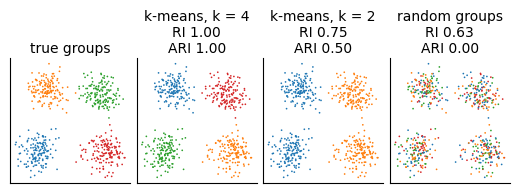

In [25]:
@partial(jax.jit, static_argnames=("ka", "kb"))
def _rand_indices(a, b, ka, kb):
    N = jax.nn.one_hot(a, ka).T @ jax.nn.one_hot(b, kb)             # contingency table
    comb2 = lambda x: x * (x - 1.0) / 2.0
    n = a.shape[0]
    s_ab, s_a, s_b, total = comb2(N).sum(), comb2(N.sum(1)).sum(), comb2(N.sum(0)).sum(), comb2(jnp.float32(n))
    ri = (total + 2.0 * s_ab - s_a - s_b) / total
    expected = s_a * s_b / total
    ari = (s_ab - expected) / (0.5 * (s_a + s_b) - expected)
    return ri, ari

def rand_indices(a, b):
    # (RI, ARI) of two labellings of the same samples
    ua, a_ = np.unique(np.asarray(a), return_inverse=True)
    ub, b_ = np.unique(np.asarray(b), return_inverse=True)
    ri, ari = _rand_indices(jnp.asarray(a_), jnp.asarray(b_), len(ua), len(ub))
    return float(ri), float(ari)

# the four groups of the previous cell: true groups and three clusterings
parts = [("true groups", yk),
         ("k-means, k = 4", fits4[4][1]),
         ("k-means, k = 2", fits4[2][1]),
         ("random groups", np.asarray(jax.random.randint(section_key(11), (len(yk),), 0, 4)))]
with plt.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 4, figsize=(5.06, 1.8))
    for a, (title, lab) in zip(axs, parts):
        ri, ari = rand_indices(yk, lab)
        a.scatter(Xkn[:, 0], Xkn[:, 1], s=1.5, c=cmap(lab), lw=0); a.set_xticks([]); a.set_yticks([]); clean(a)
        a.set_title(title if title == "true groups" else f"{title}\nRI {ri:.2f}\nARI {ari:.2f}", fontsize=10)
        print(f"{title:15s}: RI {ri:.3f}, ARI {ari:+.3f}")
    plt.tight_layout(pad=0.2, w_pad=0.4); save("gen_ari_toy.png"); plt.show()
for key_, (_, lab) in zip(["k4", "k2", "random"], parts[1:]):
    ri, ari = rand_indices(yk, lab)
    nums[f"ari_toy_{key_}"] = {"RI": round(ri, 3), "ARI": round(ari, 3)}

The random groups have a Rand index far above zero, but an adjusted Rand index of essentially zero: this is the reason for the correction. Splitting the four groups into two gives an intermediate value.

### 4.7 k-means on MNIST

With these tools we return to the digits. We ask for $k=10$ groups, once on the 50 PCA components and once on the t-SNE map, and compare them with the true digits by the ARI. The ten centres found on the PCA components can be mapped back to pixels, $\bar{\mathbf x}+\Lambda_{50}\boldsymbol\mu_c$ (with $\boldsymbol\mu_c\in\mathbb R^{50}$ the centre of cluster $c$), and shown as images.

k-means, k = 10: ARI on 50 PCA components 0.380 (42 Lloyd iterations) | on the t-SNE map 0.757 (38 Lloyd iterations)


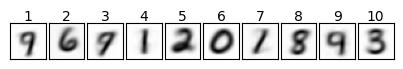

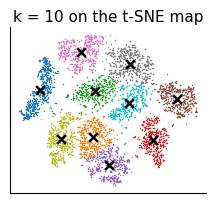

t-SNE clusters, rows = true digit, columns = cluster:
 [[  0   0   1   3   0 489   0   0   0   4]
 [528   0   2   1   0   0   4   0   0   0]
 [  7   0   7   6   0   3 507   4  12   1]
 [  1   2  11   1   1   2   5 473   2   3]
 [  6 212   1   4 227   0   0   0   2   0]
 [  6   4   7   4   1   6   0  51   2 366]
 [  0   0   0 472   1   5   0   0   0   3]
 [ 28   3   0   0  10   0   7   0 476   0]
 [  2  11 412   0   6   3   4  27   3  42]
 [  1 233   4   1 240   1   1   6  15   4]]


In [26]:
mu_Z, lab_Z, loss_Z, it_Z = kmeans(section_key(12), Z, 10)
mu_E, lab_E, loss_E, it_E = kmeans(section_key(12), E, 10)
nums["kmeans_ari_pca50"] = rand_indices(y5, lab_Z)[1]
nums["kmeans_ari_tsne"] = rand_indices(y5, lab_E)[1]
print(f"k-means, k = 10: ARI on 50 PCA components {nums['kmeans_ari_pca50']:.3f} ({int(it_Z)} Lloyd iterations)"
      f" | on the t-SNE map {nums['kmeans_ari_tsne']:.3f} ({int(it_E)} Lloyd iterations)")

cent = np.asarray(xbar + mu_Z @ V[:, :50].T)
with plt.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 10, figsize=(4.95, 0.75))
    for k_, a in enumerate(axs):
        a.imshow(cent[k_].reshape(28, 28), cmap="gray_r"); a.set_xticks([]); a.set_yticks([])
        a.set_title(f"{k_ + 1}", fontsize=10, pad=2)
    plt.subplots_adjust(wspace=0.08)
    save("gen_kmeans_centroids.png"); plt.show()

lab_En, mu_En = np.asarray(lab_E), np.asarray(mu_E)
with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(2.53, 2.15))
    for k_ in range(10):
        m = lab_En == k_; ax.scatter(En[m, 0], En[m, 1], s=1, color=cmap(k_), lw=0)
    ax.scatter(*mu_En.T, marker="x", s=40, color="k", lw=1.8)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title("k = 10 on the t-SNE map"); clean(ax)
    save("gen_kmeans_tsne.png"); plt.show()

# which digits end up in which cluster (contingency table: rows = digits, columns = clusters)
N_tab = np.zeros((10, 10), int); np.add.at(N_tab, (y5, lab_En), 1)
print("t-SNE clusters, rows = true digit, columns = cluster:\n", N_tab)

The ARI on the t-SNE map is about twice the ARI on the PCA components: k-means looks for round groups of similar size, and the t-SNE map provides them. The contingency table shows where the clustering fails; in this run two of the clusters each contain a mixture of 4s and 9s, digits whose shapes are close.

### 4.8 Number of clusters on MNIST

The same two guides on the t-SNE map of the 5000 digits, for $k=2,\dots,15$, with the exact silhouette over all 5000 points (one $5000\times5000$ distance matrix, computed once). The dotted line marks $k=10$, the number of digits; it is drawn only for comparison, k-means and the two guides do not know the labels.

k:          [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
silhouette: [0.344 0.411 0.409 0.399 0.396 0.421 0.459 0.471 0.468 0.47  0.468 0.448
 0.44  0.427]
largest silhouette at k = 9


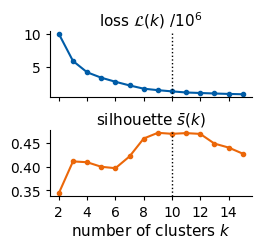

[ 426.6 s] k-means done


In [27]:
DE = jnp.sqrt(sq_dists_lowdim(E))
ks = list(range(2, 16)); loss_k, sil_k = [], []
for kk in ks:
    _, lab_, L_, _ = kmeans(section_key(13), E, kk)
    loss_k.append(float(L_)); sil_k.append(silhouette(DE, lab_, kk))
nums["kmeans_best_k_silhouette"] = int(ks[int(np.argmax(sil_k))])
nums["kmeans_silhouette_k10"] = round(sil_k[ks.index(10)], 3)
print("k:         ", ks); print("silhouette:", np.round(sil_k, 3))
print("largest silhouette at k =", nums["kmeans_best_k_silhouette"])

with plt.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(2.48, 2.35), sharex=True)
    axs[0].plot(ks, np.array(loss_k) / 1e6, "o-", color=blue, ms=3); axs[0].set_title(r"loss $\mathcal{L}(k)$ $/10^6$")
    axs[1].plot(ks, sil_k, "o-", color=orange, ms=3); axs[1].set_title(r"silhouette $\bar s(k)$")
    axs[1].set_xlabel("number of clusters $k$"); axs[1].set_xticks([2, 4, 6, 8, 10, 12, 14])
    for a in axs: a.axvline(10, color="k", ls=":", lw=1); clean(a)
    plt.tight_layout(pad=0.2, h_pad=0.6); save("gen_kmeans_choose_k.png"); plt.show()
log("k-means done")

On real data the guides are less sharp than on the toy example: the silhouette curve is flat over a range of $k$ around 10, and its maximum, printed above, need not be at the number of digits. The 4s and 9s, merged in the contingency table, are one reason.

### 4.9 k-means with scikit-learn

In scikit-learn, k-means is the estimator `sklearn.cluster.KMeans(n_clusters, init="k-means++", n_init, max_iter, random_state)`. After `fit(X)` it stores the centres in `cluster_centers_`, the labels of the training points in `labels_`, the loss $\mathcal L$ in `inertia_` and the number of Lloyd iterations in `n_iter_`; `predict(X)` assigns new points to the nearest centre, and `fit_predict(X)` returns the labels at once. Its k-means++ is the greedy variant, which draws several candidates for each new centre and keeps the best one, and its random numbers come from NumPy, not from our JAX keys. The scores live in `sklearn.metrics`: `silhouette_score(X, labels)` computes $\bar s$ from the data and the labels, and `rand_score(a, b)` and `adjusted_rand_score(a, b)` compare two labellings.

The scores are deterministic functions of the data and the labels, so they must agree with ours exactly (up to float32 rounding), and the cell asserts it. k-means started from different random centres can end in different local minima, so there we compare statistically: the loss of the two solutions and the ARI between the two partitions. One exact statement about k-means remains: a converged solution is a fixed point of Lloyd's algorithm. If scikit-learn is started from our final centres (`init=` an array of centres, `n_init=1`), it must stop at once with the same labels and the same loss.

In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, rand_score, silhouette_score

# scores of the same labellings: exact agreement
_, lab10, _, _ = kmeans(section_key(13), E, 10)
checks = [("ARI, k-means on 50 PCA comp.", nums["kmeans_ari_pca50"], adjusted_rand_score(y5, np.asarray(lab_Z))),
          ("ARI, k-means on the t-SNE map", nums["kmeans_ari_tsne"], adjusted_rand_score(y5, lab_En)),
          ("RI, random groups", rand_indices(yk, parts[3][1])[0], rand_score(yk, parts[3][1])),
          ("silhouette, toy, k = 4", sil4[2], silhouette_score(Xkn, fits4[4][1])),
          ("silhouette, t-SNE map, k = 10", silhouette(DE, lab10, 10), silhouette_score(En, np.asarray(lab10)))]
for name, ours, sk in checks:
    print(f"{name:32s}: JAX {ours:.6f} | scikit-learn {sk:.6f}")
    assert abs(ours - sk) < 1e-4

# k-means from random starts: statistical agreement
t = time.time()
sk_km = KMeans(n_clusters=10, n_init=10, random_state=0).fit(Zn)
print(f"\nscikit-learn KMeans on 50 PCA components ({time.time() - t:.1f} s, {sk_km.n_iter_} Lloyd iterations)")
print(f"loss: JAX {float(loss_Z):.1f} | scikit-learn {sk_km.inertia_:.1f}"
      f" | ARI with the digits: JAX {nums['kmeans_ari_pca50']:.3f}, scikit-learn {adjusted_rand_score(y5, sk_km.labels_):.3f}"
      f" | ARI between the two partitions {adjusted_rand_score(sk_km.labels_, np.asarray(lab_Z)):.3f}")
nums["kmeans_sklearn_pca50"] = {"loss_jax": round(float(loss_Z), 1), "loss_sklearn": round(float(sk_km.inertia_), 1),
                                "ari_digits_sklearn": round(float(adjusted_rand_score(y5, sk_km.labels_)), 3),
                                "ari_between": round(float(adjusted_rand_score(sk_km.labels_, np.asarray(lab_Z))), 3)}

# a converged solution is a fixed point of Lloyd's algorithm: exact agreement
fixed = KMeans(n_clusters=10, init=np.asarray(mu_Z), n_init=1).fit(Zn)
n_diff = int(np.sum(fixed.labels_ != np.asarray(lab_Z)))
print(f"started from our centres: {fixed.n_iter_} iteration(s), points with a different label: {n_diff},"
      f" loss {fixed.inertia_:.1f} (JAX {float(loss_Z):.1f})")
assert n_diff <= 2                                     # only float32 near-ties could differ
assert abs(fixed.inertia_ - float(loss_Z)) < 1e-4 * float(loss_Z)

ARI, k-means on 50 PCA comp.    : JAX 0.380302 | scikit-learn 0.380302
ARI, k-means on the t-SNE map   : JAX 0.757295 | scikit-learn 0.757295
RI, random groups               : JAX 0.626294 | scikit-learn 0.626294
silhouette, toy, k = 4          : JAX 0.691623 | scikit-learn 0.691623
silhouette, t-SNE map, k = 10   : JAX 0.468421 | scikit-learn 0.468421



scikit-learn KMeans on 50 PCA components (0.9 s, 30 Lloyd iterations)
loss: JAX 150274.5 | scikit-learn 150262.8 | ARI with the digits: JAX 0.380, scikit-learn 0.380 | ARI between the two partitions 0.930
started from our centres: 1 iteration(s), points with a different label: 0, loss 150274.5 (JAX 150274.5)


All scores agree to the printed digits. The two k-means solutions from random starts reach losses that differ by a small fraction, and their partitions agree closely without being identical: both are local minima of the same loss, found from different starting centres. Started from our centres, scikit-learn stops after one iteration with our labels and our loss, as it must.

### 4.10 DBSCAN

k-means cuts space into convex cells around the centres, so it finds round clusters. **DBSCAN**, density-based spatial clustering of applications with noise (M. Ester, H.-P. Kriegel, J. Sander, X. Xu, KDD 1996), instead grows clusters from dense regions. It has two parameters, a radius $\varepsilon$ and a minimum number of points $m$:

* a **core point** has at least $m$ points (itself included) within distance $\varepsilon$;
* a **border point** is not a core point but lies within $\varepsilon$ of one;
* every other point is **noise**.

A cluster is a set of core points that can be reached from each other in steps shorter than $\varepsilon$, together with their border points. The algorithm:

1. count the neighbours within $\varepsilon$ of every point and mark the core points;
2. take a core point not yet in a cluster and start a new cluster with it;
3. add every point within $\varepsilon$ of a core point of the cluster; repeat until no point is added (a breadth-first search; border points join but do not expand the cluster);
4. repeat 2–3 until every core point is in a cluster; the points never reached are noise.

DBSCAN needs no number of clusters, follows clusters of any shape and leaves isolated points unassigned.

### 4.11 DBSCAN implementation in JAX

The neighbour matrix is computed in JAX; the search itself is a short Python loop over a queue, which is easier to read than a compiled version and fast enough for a few thousand points.

The first figure shows the three kinds of points on a small example: 70 points on two half-moons and 8 scattered points, with $\varepsilon=0.25$ and $m=4$.

{'clusters': 3, 'core': 65, 'border': 6, 'noise': 7}


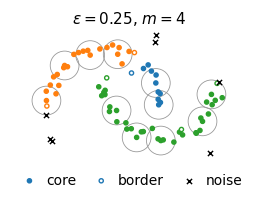

In [29]:
def dbscan(X, eps, min_pts):
    # labels (-1 = noise) and the core-point mask
    nb = np.asarray(sq_dists(jnp.asarray(X)) <= eps ** 2)        # neighbour matrix, itself included
    core = nb.sum(axis=1) >= min_pts
    labels = np.full(len(nb), -1)
    c = 0
    for i in np.flatnonzero(core):
        if labels[i] != -1:
            continue
        labels[i] = c; queue = deque([i])
        while queue:                                              # breadth-first search from core point i
            j = queue.popleft()
            if not core[j]:
                continue                                          # border points do not expand the cluster
            for q in np.flatnonzero(nb[j]):
                if labels[q] == -1:
                    labels[q] = c; queue.append(q)
        c += 1
    return labels, core

def make_moons(key, n, noise):
    n_out = n // 2; n_in = n - n_out
    t_out, t_in = jnp.linspace(0, jnp.pi, n_out), jnp.linspace(0, jnp.pi, n_in)
    X = jnp.concatenate([jnp.stack([jnp.cos(t_out), jnp.sin(t_out)], 1),
                         jnp.stack([1 - jnp.cos(t_in), 0.5 - jnp.sin(t_in)], 1)])
    return X + noise * jax.random.normal(key, X.shape), np.r_[np.zeros(n_out, int), np.ones(n_in, int)]

k1, k2 = jax.random.split(section_key(14))
Xd = np.r_[np.asarray(make_moons(k1, 70, 0.07)[0]),
           np.asarray(jax.random.uniform(k2, (8, 2), minval=jnp.array([-1.2, -0.8]), maxval=jnp.array([2.2, 1.3])))]
eps_d, m_d = 0.25, 4
lab_d, core = dbscan(Xd, eps_d, m_d)
noise_d = lab_d == -1; border = ~core & ~noise_d
nums["dbscan_sketch"] = {"clusters": int(lab_d.max() + 1), "core": int(core.sum()), "border": int(border.sum()), "noise": int(noise_d.sum())}
print(nums["dbscan_sketch"])

with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(2.75, 1.95))
    for i in np.flatnonzero(core)[::6]:
        ax.add_patch(plt.Circle(Xd[i], eps_d, fill=False, color="#999999", lw=0.6))
    ax.scatter(*Xd[core].T, s=9, c=cmap(lab_d[core]), label="core")
    ax.scatter(*Xd[border].T, s=9, facecolors="white", edgecolors=cmap(lab_d[border]), lw=1.0, label="border")
    ax.scatter(*Xd[noise_d].T, s=14, marker="x", color="k", lw=1.0, label="noise")
    ax.set_aspect("equal"); ax.axis("off")
    ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 0.0), handletextpad=0.2, columnspacing=0.8)
    ax.set_title(rf"$\varepsilon = {eps_d}$, $m = {m_d}$")
    save("gen_dbscan_sketch.png"); plt.show()

The decisive test is a shape that k-means cannot represent. Two half-moons, points on two interlocking half-circles plus Gaussian noise, are the classic case: each moon is a curved, elongated cluster, and the line that best splits the data into two round halves cuts both moons. We cluster 500 such points with k-means ($k=2$) and with DBSCAN ($\varepsilon=0.2$, $m=5$) and score both against the true moons with the ARI.

{'moons_ari_kmeans': 0.241, 'moons_ari_dbscan': 1.0, 'moons_dbscan_clusters': 2, 'moons_dbscan_noise': 0}


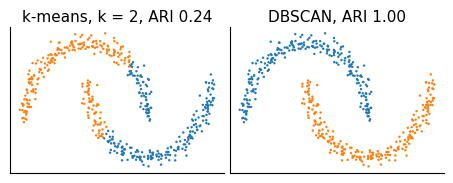

In [30]:
Xm, ym = make_moons(section_key(15), 500, 0.06)
_, lab_km, _, _ = kmeans(section_key(16), Xm, 2)
lab_db, _ = dbscan(Xm, 0.2, 5)
nums["moons_ari_kmeans"] = rand_indices(ym, lab_km)[1]
nums["moons_ari_dbscan"] = rand_indices(ym, lab_db)[1]
nums["moons_dbscan_clusters"] = int(lab_db.max() + 1); nums["moons_dbscan_noise"] = int((lab_db == -1).sum())
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in nums.items() if k.startswith("moons")})

Xmn = np.asarray(Xm)
with plt.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(4.4, 1.7))
    for a, lab, title in zip(axs, [np.asarray(lab_km), lab_db],
                             [f"k-means, k = 2, ARI {nums['moons_ari_kmeans']:.2f}", f"DBSCAN, ARI {nums['moons_ari_dbscan']:.2f}"]):
        cols = np.where((lab >= 0)[:, None], cmap(lab % 10), np.array([[0.5, 0.5, 0.5, 1.0]]))
        a.scatter(Xmn[:, 0], Xmn[:, 1], s=3, c=cols, lw=0); a.set_title(title)
        a.set_xticks([]); a.set_yticks([]); clean(a)
    plt.tight_layout(pad=0.2, w_pad=0.4); save("gen_kmeans_moons.png"); plt.show()

DBSCAN recovers both moons exactly (ARI 1), while k-means, bound to convex cells, cuts them and reaches a much lower ARI.

### 4.12 DBSCAN with scikit-learn

scikit-learn's `sklearn.cluster.DBSCAN(eps, min_samples)` has the same two parameters; `min_samples` counts the point itself, like our $m$. After `fit(X)` the labels are in `labels_`, with $-1$ for noise as in our implementation, and the indices of the core points in `core_sample_indices_`; `fit_predict(X)` returns the labels directly. There is no `predict`: DBSCAN, like t-SNE, describes only the points it was given.

DBSCAN is deterministic, and the core points and the noise points are fixed by the definitions, so they must agree exactly with ours. Only two details may differ: the numbering of the clusters, which the ARI ignores, and a border point within $\varepsilon$ of core points of two different clusters, which joins whichever cluster reaches it first. The cell asserts that the core points and the noise points coincide, on the small example and on the half-moons, and prints the ARI between the two labellings.

In [31]:
from sklearn.cluster import DBSCAN

for name, X_, eps_, m_, ours in [("small example", Xd, eps_d, m_d, lab_d), ("half-moons", Xmn, 0.2, 5, lab_db)]:
    sk_db = DBSCAN(eps=eps_, min_samples=m_).fit(X_)
    core_ours = np.flatnonzero(dbscan(X_, eps_, m_)[1])
    same_core = np.array_equal(np.sort(sk_db.core_sample_indices_), core_ours)
    same_noise = np.array_equal(sk_db.labels_ == -1, ours == -1)
    ari_ = adjusted_rand_score(sk_db.labels_, ours)
    print(f"{name:13s}: {sk_db.labels_.max() + 1} clusters | same core points: {same_core} | same noise points: {same_noise}"
          f" | ARI between the two labellings {ari_:.3f}")
    assert same_core and same_noise

small example: 3 clusters | same core points: True | same noise points: True | ARI between the two labellings 1.000
half-moons   : 2 clusters | same core points: True | same noise points: True | ARI between the two labellings 1.000


Both implementations find the same core and noise points, and here also the same clusters (ARI 1 between the labellings).

#### Exercises

* Run k-means with $k=5$ and $k=15$ on the t-SNE map. Which digits are merged, which are split? Use the contingency table.
* Replace k-means++ by a uniformly random choice of the initial centres and use `n_init=1`. How often does the toy example with four groups end in a poor local minimum? Run it for 100 keys with `jax.vmap`.
* Run DBSCAN on the t-SNE map of the digits. Find $\varepsilon$ and $m$ that give about ten clusters, and compare the ARI (on the non-noise points) with k-means.
* Compute the silhouette for k-means with $k=2$ on the half-moons, and for DBSCAN. Which clustering does the silhouette prefer, and why is that misleading here?

## 5. Summary

PCA projects the data on the directions of largest variance, the leading eigenvectors of the covariance matrix. It is linear, exact and fast, it can be applied to new samples, and its eigenvalues say how much variance a projection keeps; for the MNIST digits a few components keep the coarse shape of the images but do not separate all ten digits. t-SNE gives up the large distances to keep the neighbours: it turns distances into neighbour probabilities, in the data with a Gaussian of adaptive width and in the map with a heavy-tailed Student-t kernel, and minimises the Kullback–Leibler divergence between the two. Its maps separate the digits far better, but only the neighbourhoods in a map carry meaning, not the positions, gaps or sizes of the clusters.

Clustering turns such pictures into labels. k-means finds round groups by alternating assignments and centre updates, needs the number of clusters from outside, and can be guided by the elbow of its loss and by the silhouette score; DBSCAN grows clusters of any shape from dense regions and marks isolated points as noise. When true classes are known, the adjusted Rand index scores a clustering against them and is zero for chance. For every method the JAX implementation and scikit-learn agree exactly where the computation is deterministic, and statistically where random starts or approximations make the results differ.